# 四层探测器缪子散射成像：PoCA 基线 Notebook

这是本项目的**学习版分析 Notebook**。它从 Geant4 导出的 `muon_tracks.csv` 出发，依次完成：

1. 检查四层探测器击中数据；
2. 理解散射角与 PoCA 点；
3. 将 PoCA 点累积成固定体素图像；
4. 在不同事件数下计算 IoU 和定位误差。

建议严格从上到下逐格运行。每个代码单元前都说明了“为什么需要这一步”。

## 0. 这份数据在物理上表示什么

Geant4 中有四个平面探测器：上游两层用于拟合**入射轨迹**，下游两层用于拟合**出射轨迹**。缪子穿过 U 型铝目标后会发生多重库仑散射，因此两条直线会有一个小夹角。

PoCA（Point of Closest Approach）把两条直线最近点连线的中点，近似为该缪子主要发生散射的位置。这个近似并不完美，但简单、可解释，适合做第一条基线。

In [87]:
# 导入本 Notebook 需要的库。
# pandas：读取和整理 CSV；numpy：数值计算；matplotlib：绘图。
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 让图中的中文在大多数 macOS 环境里更容易显示。
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# Notebook 位于 muon_analysis 文件夹，因此 CSV 默认就在同一目录。
DATA_PATH = Path('muon_tracks.csv')
print('准备读取：', DATA_PATH.resolve())

准备读取： /Users/xuyaoyang/geant4-test/muon_analysis/muon_tracks.csv


## 1. 读取 CSV，并先确认数据是否完整

这一格不做任何成像。先查看列名和前几行，确认 Geant4 输出中确实包含四层击中、PoCA 坐标和散射角。这样若后面报错，能更快判断是数据问题还是算法问题。

In [88]:
# 读取 Geant4 输出。每一行对应一条通过四层探测器的完整缪子径迹。
df = pd.read_csv(DATA_PATH)

print(f'完整径迹数：{len(df):,}')
print('\nCSV 字段：')
print(df.columns.tolist())
display(df.head())

完整径迹数：9,975

CSV 字段：
['event', 'up1_x_mm', 'up1_y_mm', 'up1_z_mm', 'up2_x_mm', 'up2_y_mm', 'up2_z_mm', 'down1_x_mm', 'down1_y_mm', 'down1_z_mm', 'down2_x_mm', 'down2_y_mm', 'down2_z_mm', 'poca_x_mm', 'poca_y_mm', 'poca_z_mm', 'theta_x_mrad', 'theta_y_mrad', 'theta_mrad']


,event,up1_x_mm,up1_y_mm,up1_z_mm,up2_x_mm,up2_y_mm,up2_z_mm,down1_x_mm,down1_y_mm,down1_z_mm,down2_x_mm,down2_y_mm,down2_z_mm,poca_x_mm,poca_y_mm,poca_z_mm,theta_x_mrad,theta_y_mrad,theta_mrad
0,0,-110.8530,35.32500,-405,-110.8890,35.28940,-305,-111.0080,35.11960,295,-111.0400,35.11940,395,-111.0050,35.1248,143.9500,0.036531,0.353843,0.355724
1,1,139.8240,111.57700,-405,139.8520,111.52700,-305,139.8900,111.36100,295,139.9050,111.32700,395,139.7530,111.6820,-630.3210,-0.123838,0.156143,0.199290
2,2,-15.3030,47.05700,-405,-15.2627,47.04200,-305,-14.8524,46.91880,295,-14.7597,46.94070,395,-15.0604,46.9292,109.2800,0.525042,0.368033,0.641184
3,3,-143.9370,77.24070,-405,-143.9910,77.19090,-305,-144.0890,77.02930,295,-144.0550,76.99320,395,-144.1750,77.0772,23.5229,0.880683,0.137576,0.891363
4,4,37.0839,8.19737,-405,37.1205,8.24551,-305,37.0023,9.26933,295,36.9045,9.50702,395,37.2759,8.4129,-47.1158,-1.344200,1.895550,2.323780


### 字段速查

- `up1_*`、`up2_*`：上游两层的击中坐标；
- `down1_*`、`down2_*`：下游两层的击中坐标；
- `poca_*`：在 C++ 端由两条拟合直线计算的 PoCA 坐标；
- `theta_x_mrad`、`theta_y_mrad`：x-z 和 y-z 平面上的投影散射角；
- `theta_mrad`：总散射角，后面用它的平方作为体素权重。

坐标单位是 mm，角度单位是 mrad。

In [89]:
# 如果下面缺少任何字段，说明当前 CSV 不是本项目需要的完整输出格式。
REQUIRED_COLUMNS = {
    'up1_x_mm', 'up1_y_mm', 'up1_z_mm',
    'up2_x_mm', 'up2_y_mm', 'up2_z_mm',
    'down1_x_mm', 'down1_y_mm', 'down1_z_mm',
    'down2_x_mm', 'down2_y_mm', 'down2_z_mm',
    'poca_x_mm', 'poca_y_mm', 'poca_z_mm', 'theta_mrad',
}
missing = REQUIRED_COLUMNS - set(df.columns)
assert not missing, f'CSV 缺少字段：{sorted(missing)}'
print('✓ CSV 字段检查通过。')

✓ CSV 字段检查通过。


## 2. 看一眼上下游击中位置

理想入射模式下，探测器平面上的击中分布接近均匀；这张图本身不直接显示 U 型目标。真正携带目标信息的是上下游轨迹之间的变化，即散射角和 PoCA 点。

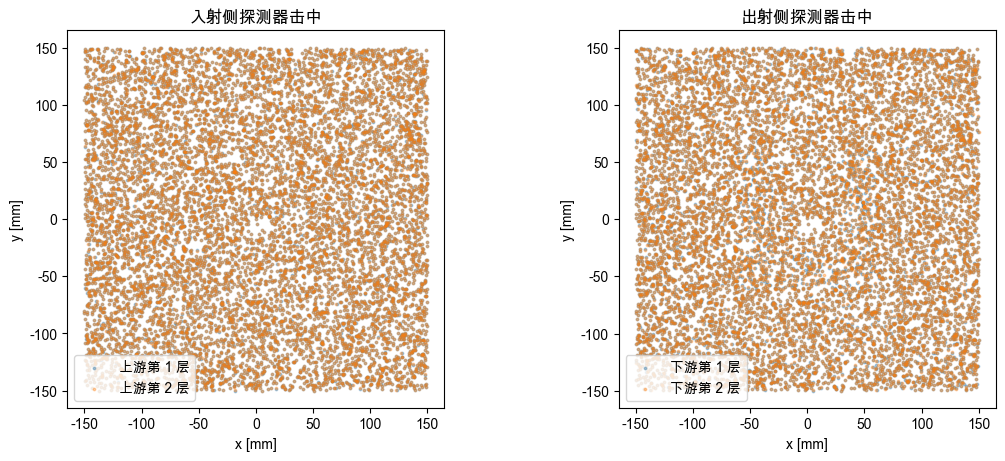

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# 上游：缪子进入目标前的两次位置测量。
axes[0].scatter(df['up1_x_mm'], df['up1_y_mm'], s=3, alpha=0.35, label='上游第 1 层')
axes[0].scatter(df['up2_x_mm'], df['up2_y_mm'], s=3, alpha=0.35, label='上游第 2 层')
axes[0].set(title='入射侧探测器击中', xlabel='x [mm]', ylabel='y [mm]')
axes[0].set_aspect('equal')
axes[0].legend()

# 下游：缪子穿过目标后的两次位置测量。
axes[1].scatter(df['down1_x_mm'], df['down1_y_mm'], s=3, alpha=0.35, label='下游第 1 层')
axes[1].scatter(df['down2_x_mm'], df['down2_y_mm'], s=3, alpha=0.35, label='下游第 2 层')
axes[1].set(title='出射侧探测器击中', xlabel='x [mm]', ylabel='y [mm]')
axes[1].set_aspect('equal')
axes[1].legend()
plt.show()

## 3. 散射角分布

`theta_mrad` 越大，通常意味着缪子在目标附近经历了更明显的散射。后续固定体素 PoCA 不只是计数，而是累加 $\theta^2$，从而使大散射事件对图像贡献更大。

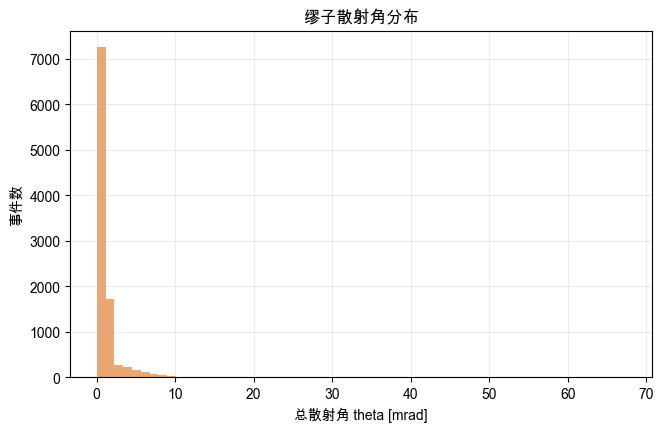

count    9975.000000
mean        1.205232
std         1.699581
min         0.003353
25%         0.486866
50%         0.780169
75%         1.178480
max        67.309300
Name: theta_mrad, dtype: float64


In [91]:
plt.figure(figsize=(7.5, 4.5))
plt.hist(df['theta_mrad'], bins=60, histtype='stepfilled', alpha=0.55, color='#d95f02')
plt.xlabel('总散射角 theta [mrad]')
plt.ylabel('事件数')
plt.title('缪子散射角分布')
plt.grid(alpha=0.25)
plt.show()

print(df['theta_mrad'].describe())

## 4. 先观察 PoCA 三维点云

颜色表示散射角。三维点云适合帮助你建立直觉，但论文中通常还需要体素图，因为体素图可以稳定地计算轮廓、IoU 和定位误差。

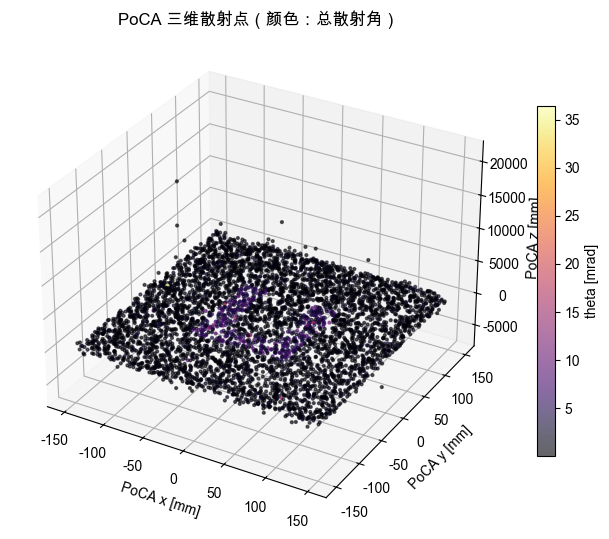

In [92]:
fig = plt.figure(figsize=(8, 6.5))
ax = fig.add_subplot(111, projection='3d')

# 使用少量点可以让三维图更清晰；若数据更少则直接使用全部。
plot_df = df.sample(min(5000, len(df)), random_state=20260921)
scatter = ax.scatter(
    plot_df['poca_x_mm'], plot_df['poca_y_mm'], plot_df['poca_z_mm'],
    c=plot_df['theta_mrad'], s=4, alpha=0.6, cmap='inferno'
)
ax.set(xlabel='PoCA x [mm]', ylabel='PoCA y [mm]', zlabel='PoCA z [mm]',
       title='PoCA 三维散射点（颜色：总散射角）')
fig.colorbar(scatter, ax=ax, shrink=0.7, label='theta [mrad]')
plt.show()

## 5. 设定固定体素 PoCA 的参数

这些参数就是你之后做改进算法时必须固定的**基线条件**。先不要随意改动；改参数应该单独成为一组实验，并记录到论文和 Git 提交中。

In [93]:
# 成像区域覆盖 U 型目标（目标在 xy 平面约为 ±60 mm）。
XY_LIMIT_MM = 90.0
Z_LIMIT_MM = 100.0

# 32³ 是当前论文基线网格。增大 BINS 会得到更细图像，
# 但在低统计量下也会让每个体素更稀疏、更噪。
BINS = 32

# 体素权重：每个体素累加 theta_mrad²。
WEIGHT_DESCRIPTION = 'sum(theta_mrad²)'

print(f'成像范围：x/y ±{XY_LIMIT_MM:g} mm，z ±{Z_LIMIT_MM:g} mm')
print(f'体素网格：{BINS} × {BINS} × {BINS}')
print(f'体素权重：{WEIGHT_DESCRIPTION}')

成像范围：x/y ±90 mm，z ±100 mm
体素网格：32 × 32 × 32
体素权重：sum(theta_mrad²)


## 6. 将 PoCA 点累积到三维体素

函数做三件事：

1. 去掉成像范围外的 PoCA 点；
2. 用 `numpy.histogramdd` 把三维空间分成规则体素；
3. 在每个体素中累加 $\theta^2$。

注意：函数不修改原始 `df`，因此每次实验都可以从同一份 Geant4 数据公平比较。

In [94]:
def voxelize_poca(data: pd.DataFrame, bins: int = BINS,
                  xy_limit: float = XY_LIMIT_MM,
                  z_limit: float = Z_LIMIT_MM):
    """把 PoCA 事件变成固定网格的三维散射强度。

    参数
    ----
    data : 需要重建的事件子集。
    bins : x、y、z 三个方向使用的体素数。
    xy_limit, z_limit : 成像范围半宽，单位 mm。

    返回
    ----
    volume : shape=(bins, bins, bins) 的体素强度数组。
    edges : 三个方向的体素边界。
    valid : 实际落入成像范围的事件。它用于统计，而非修改输入数据。
    """
    # 仅保留落入重建区域的 PoCA 点；范围外的点不参与体素累积。
    valid = data[
        (data['poca_x_mm'].abs() <= xy_limit)
        & (data['poca_y_mm'].abs() <= xy_limit)
        & (data['poca_z_mm'].abs() <= z_limit)
    ].copy()

    # histogramdd 需要每个方向的分箱边界，而不是体素中心。
    edges = [
        np.linspace(-xy_limit, xy_limit, bins + 1),
        np.linspace(-xy_limit, xy_limit, bins + 1),
        np.linspace(-z_limit, z_limit, bins + 1),
    ]

    # theta² 让高散射事件比近似直行事件拥有更大权重。
    weights = valid['theta_mrad'].to_numpy() ** 2
    volume, edges = np.histogramdd(
        valid[['poca_x_mm', 'poca_y_mm', 'poca_z_mm']].to_numpy(),
        bins=edges,
        weights=weights,
    )
    return volume, edges, valid


volume, voxel_edges, valid_events = voxelize_poca(df)
print(f'进入成像范围的 PoCA 点：{len(valid_events):,} / {len(df):,}')
print('体素数组形状：', volume.shape)

进入成像范围的 PoCA 点：1,649 / 9,975
体素数组形状： (32, 32, 32)


## 7. 得到最基础的 U 型目标 XY 图像

这里沿 z 方向把三维体素强度相加，得到 xy 投影。你应该能看到开口朝 +y 的 U 型大致轮廓。若看不到，先检查：是否运行了 Geant4、是否使用正确 CSV、成像范围是否仍覆盖目标。

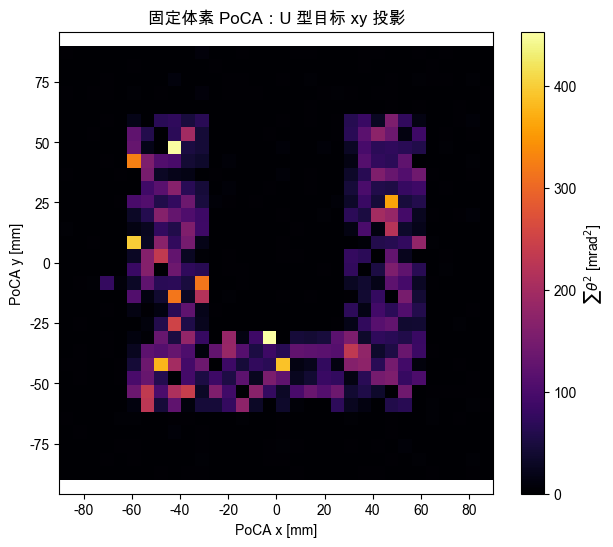

In [95]:
# axis=2 对应 z 方向；求和后留下 x-y 平面强度图。
xy_image = volume.sum(axis=2)

plt.figure(figsize=(7, 6))
mesh = plt.pcolormesh(
    voxel_edges[0], voxel_edges[1], xy_image.T,
    shading='auto', cmap='inferno'
)
plt.colorbar(mesh, label=r'$\sum \theta^2$ [mrad$^2$]')
plt.xlabel('PoCA x [mm]')
plt.ylabel('PoCA y [mm]')
plt.title('固定体素 PoCA：U 型目标 xy 投影')
plt.axis('equal')
plt.show()

## 8. 构造 U 型真值掩膜，并定义评价指标

IoU 需要真实目标轮廓。这里的真值掩膜严格对应 Geant4 中的 U 型铝目标：外尺寸 120 mm × 120 mm、壁厚 30 mm、开口朝 +y。

为了不让不同事件数各自“挑选最有利阈值”，采用**等面积 Top-k**：预测图中取强度最高的 k 个像素，且 k 固定为真值掩膜的像素数。

In [96]:
def u_target_mask(x_centers: np.ndarray, y_centers: np.ndarray) -> np.ndarray:
    """返回与 DetectorConstruction.cc 一致的 U 型二维真值掩膜。"""
    x_grid, y_grid = np.meshgrid(x_centers, y_centers, indexing='ij')

    # U 的底边：y 从 -60 到 -30 mm。
    bottom = (np.abs(x_grid) <= 60.0) & (y_grid >= -60.0) & (y_grid <= -30.0)
    # 左、右竖边：x 分别位于 [-60, -30] 与 [30, 60] mm。
    left = (x_grid >= -60.0) & (x_grid <= -30.0) & (y_grid >= -30.0) & (y_grid <= 60.0)
    right = (x_grid >= 30.0) & (x_grid <= 60.0) & (y_grid >= -30.0) & (y_grid <= 60.0)
    return bottom | left | right


def evaluate_xy_image(image: np.ndarray, x_centers: np.ndarray, y_centers: np.ndarray):
    """计算等面积 IoU 和散射强度质心定位误差。"""
    truth = u_target_mask(x_centers, y_centers)
    k = int(truth.sum())

    # 强度最高的 k 个体素像素视为重建得到的目标区域。
    predicted = np.zeros_like(truth, dtype=bool)
    top_indices = np.argpartition(image.ravel(), -k)[-k:]
    predicted.ravel()[top_indices] = True

    intersection = np.logical_and(predicted, truth).sum()
    union = np.logical_or(predicted, truth).sum()
    iou = intersection / union if union else np.nan

    # 强度加权质心与真值掩膜几何中心的距离定义为定位误差。
    x_grid, y_grid = np.meshgrid(x_centers, y_centers, indexing='ij')
    total = image.sum()
    rec_x = (image * x_grid).sum() / total
    rec_y = (image * y_grid).sum() / total
    true_x, true_y = x_grid[truth].mean(), y_grid[truth].mean()
    localization_error_mm = np.hypot(rec_x - true_x, rec_y - true_y)
    return iou, localization_error_mm, truth, predicted


x_centers = (voxel_edges[0][:-1] + voxel_edges[0][1:]) / 2
y_centers = (voxel_edges[1][:-1] + voxel_edges[1][1:]) / 2
iou, loc_error, truth_mask, predicted_mask = evaluate_xy_image(xy_image, x_centers, y_centers)
print(f'全部事件基线 IoU：{iou:.4f}')
print(f'全部事件定位误差：{loc_error:.4f} mm')

全部事件基线 IoU：0.8409
全部事件定位误差：3.8045 mm


## 9. 低统计量：只改变事件数，其他条件保持不变

这一步是论文的基线实验。每个事件数重复随机抽样多次，报告均值和标准差，避免一次抽样的偶然性被误认为算法效果。这里使用与已完成基线实验一致的随机种子和事件数。

In [97]:
EVENT_COUNTS = [1000, 3000, 5000]
REPEATS = 5
RANDOM_SEED = 20260921

rng = np.random.default_rng(RANDOM_SEED)
records = []

for n_events in EVENT_COUNTS:
    for repeat in range(REPEATS):
        # 无放回抽样：同一次重建中同一条缪子事件不会被重复使用。
        subset = df.iloc[rng.choice(len(df), size=n_events, replace=False)]
        sub_volume, sub_edges, sub_valid = voxelize_poca(subset)
        sub_image = sub_volume.sum(axis=2)
        sub_iou, sub_error, _, _ = evaluate_xy_image(sub_image, x_centers, y_centers)
        records.append({
            'event_count': n_events,
            'repeat': repeat + 1,
            'poca_points_in_volume': len(sub_valid),
            'iou': sub_iou,
            'localization_error_mm': sub_error,
        })

results = pd.DataFrame(records)
summary = results.groupby('event_count').agg(
    repeats=('repeat', 'count'),
    iou_mean=('iou', 'mean'), iou_std=('iou', 'std'),
    error_mean=('localization_error_mm', 'mean'),
    error_std=('localization_error_mm', 'std'),
).reset_index()
display(summary)

,event_count,repeats,iou_mean,iou_std,error_mean,error_std
0,1000,5,0.283577,0.025626,9.464461,6.045081
1,3000,5,0.380200,0.022851,7.129148,4.772667
2,5000,5,0.591559,0.020192,4.363651,1.515423


## 10. 画出事件数与图像质量的关系

理想情况下，事件数增加时 IoU 上升、定位误差下降。若你在改动算法后重新运行这部分，就能和固定体素 PoCA 基线进行公平对比。

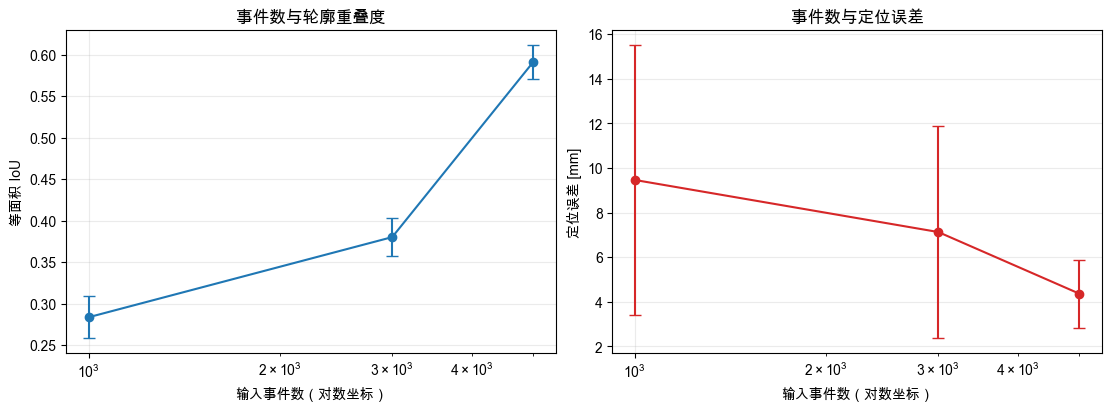

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

axes[0].errorbar(summary['event_count'], summary['iou_mean'], yerr=summary['iou_std'],
                 marker='o', capsize=4, color='#1f77b4')
axes[0].set_xscale('log')
axes[0].set(xlabel='输入事件数（对数坐标）', ylabel='等面积 IoU', title='事件数与轮廓重叠度')
axes[0].grid(alpha=0.25)

axes[1].errorbar(summary['event_count'], summary['error_mean'], yerr=summary['error_std'],
                 marker='o', capsize=4, color='#d62728')
axes[1].set_xscale('log')
axes[1].set(xlabel='输入事件数（对数坐标）', ylabel='定位误差 [mm]', title='事件数与定位误差')
axes[1].grid(alpha=0.25)
plt.show()

## 11. 下一步要做什么

你现在已经完成了传统固定体素 PoCA 的学习和复现实验。下一步是**散射角筛选 POCA**：

1. 在重建前加一条 `theta_mrad >= threshold` 的筛选；
2. 扫描多个阈值，而不是凭图像主观选择；
3. 对每个阈值重复本 Notebook 的低统计量实验；
4. 与这里的 IoU、定位误差和运行时间比较；
5. 将最优参数、随机种子、图和表写进论文第 6、7 章，并提交 GitHub。

**重要原则：** 每次只改变一个核心变量。否则即使图像变好，也无法说明真正起作用的是哪一个改动。

## 12. 散射角筛选：筛掉哪些事件？

散射角筛选只改变事件集合，不改变 PoCA、体素大小或 `theta²` 权重。对于给定的入射事件子集，保留 `theta_mrad >= theta_min_mrad` 的事件。`theta_min_mrad = 0` 就是没有筛选的基线。

注意：阈值不是越大越好。阈值提高会减少小角散射背景，但也会丢掉有效事件；必须看 IoU、定位误差和保留比例三者的平衡。

In [99]:
def filter_by_scattering_angle(events: pd.DataFrame, theta_min_mrad: float) -> pd.DataFrame:
    """保留散射角不小于阈值的事件，不修改原始 DataFrame。"""
    return events.loc[events['theta_mrad'] >= theta_min_mrad].copy()

# 第一轮阈值扫描。0 mrad 是固定体素 PoCA 基线。
ANGLE_THRESHOLDS_MRAD = [0.0, 0.5, 1.0, 2.0, 4.0, 6.0]

## 13. 读取正式阈值扫描结果

正式实验由 `run_angle_filter_experiment.py` 完成：对 1000、3000、5000 个入射事件各随机重复 5 次，并保证同一次抽样下每个阈值使用完全相同的入射事件。下面读取输出结果，而不是在 Notebook 中重新做一遍大量循环。

In [100]:
RESULTS_PATH = Path('angle_filter_results/angle_filter_metrics_summary.csv')
angle_summary = pd.read_csv(RESULTS_PATH)
angle_summary[['event_count', 'theta_min_mrad', 'retention_ratio_mean',
               'iou_mean', 'localization_error_mm_mean']]

,event_count,theta_min_mrad,retention_ratio_mean,iou_mean,localization_error_mm_mean
0,1000,0.0,1.000000,0.283577,9.464461
1,1000,0.5,0.735800,0.280104,9.464031
2,1000,1.0,0.332600,0.287685,9.559877
3,1000,2.0,0.108600,0.281768,9.736179
4,1000,4.0,0.059200,0.251606,11.614781
5,1000,6.0,0.026000,0.208530,16.383035
6,3000,0.0,1.000000,0.380200,7.129148
7,3000,0.5,0.735467,0.380200,7.125207
8,3000,1.0,0.341867,0.425316,7.135979
9,3000,2.0,0.109733,0.456389,7.318041


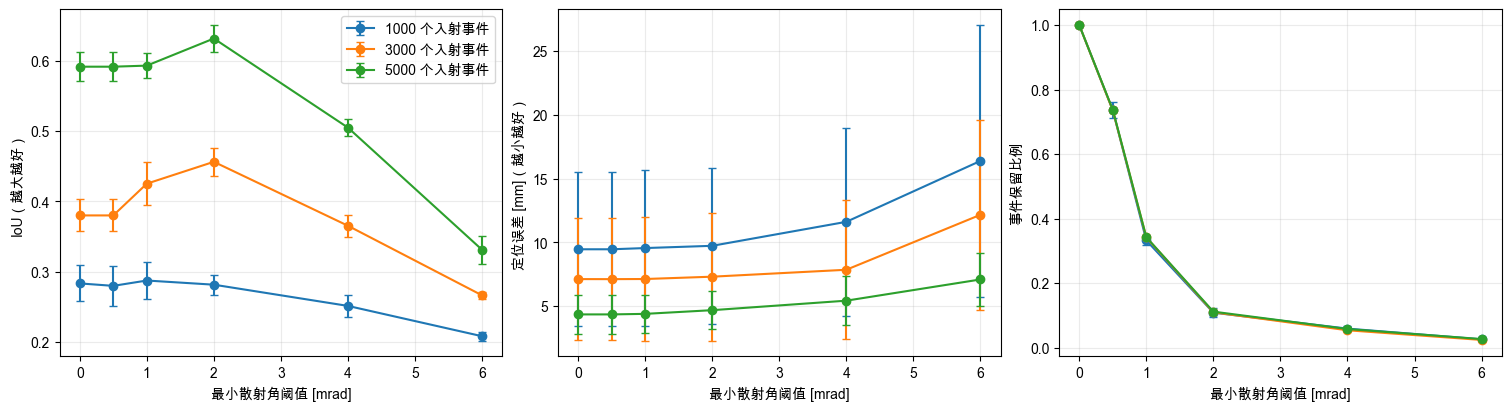

In [101]:
# 同一输入事件数下，分别查看轮廓质量、定位精度与事件保留比例。
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plots = [
    ('iou_mean', 'iou_std', 'IoU（越大越好）'),
    ('localization_error_mm_mean', 'localization_error_mm_std', '定位误差 [mm]（越小越好）'),
    ('retention_ratio_mean', 'retention_ratio_std', '事件保留比例'),
]
for ax, (mean_col, std_col, ylabel) in zip(axes, plots):
    for event_count, group in angle_summary.groupby('event_count'):
        ax.errorbar(group['theta_min_mrad'], group[mean_col], yerr=group[std_col],
                    marker='o', capsize=3, label=f'{event_count} 个入射事件')
    ax.set(xlabel='最小散射角阈值 [mrad]', ylabel=ylabel)
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 14. 如何解释这一轮结果

本轮理想源 U 型铝目标实验中，`2 mrad` 在 3000 和 5000 个入射事件下提升了 IoU，但定位误差没有同步改善；`4–6 mrad` 筛选过严，保留事件过少，轮廓和定位都变差。

因此当前可得出的结论是：**中等强度的散射角筛选有改善轮廓恢复的潜力，但尚不能宣称整体成像性能全面提升。** 下一步需要将 `1–3 mrad` 附近作为候选范围，结合散射角截断加权和自适应体素进一步验证。

## 15. 散射角截断加权：为什么要限制极端大角度事件？

PoCA 基线使用 `theta_mrad²` 作为体素权重。它能突出明显散射，但极端大散射角事件也可能让少数体素异常明亮、拉偏强度质心。截断加权保持事件位置不变，仅将权重改为：

`w_i = min(theta_i², theta_cap²)`

本实验固定 `theta >= 2 mrad`，扫描不同 `theta_cap`，检查是否能同时改善轮廓和定位。

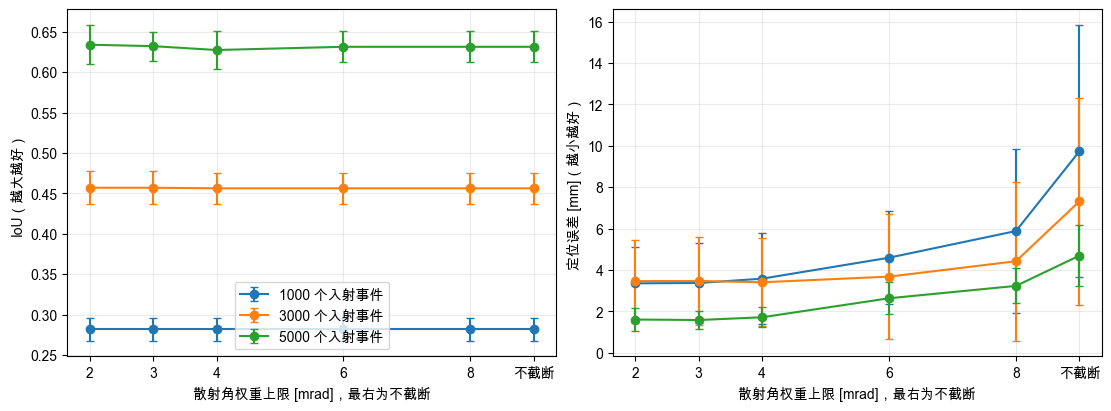

In [102]:
WEIGHTING_RESULTS_PATH = Path('angle_weighting_results/angle_weighting_metrics_summary.csv')
weighting_summary = pd.read_csv(WEIGHTING_RESULTS_PATH)

# 只画 theta >= 2 mrad 的截断加权方案；基线仍保留在 CSV 中。
plot_data = weighting_summary[weighting_summary['theta_min_mrad'] == 2.0].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for event_count, group in plot_data.groupby('event_count'):
    group = group.sort_values('cap_display_mrad')
    axes[0].errorbar(group['cap_display_mrad'], group['iou_mean'], yerr=group['iou_std'],
                     marker='o', capsize=3, label=f'{event_count} 个入射事件')
    axes[1].errorbar(group['cap_display_mrad'], group['localization_error_mm_mean'],
                     yerr=group['localization_error_mm_std'], marker='o', capsize=3,
                     label=f'{event_count} 个入射事件')
for ax, ylabel in zip(axes, ['IoU（越大越好）', '定位误差 [mm]（越小越好）']):
    ax.set(xlabel='散射角权重上限 [mrad]，最右为不截断', ylabel=ylabel)
    ax.set_xticks([2, 3, 4, 6, 8, 9])
    ax.set_xticklabels(['2', '3', '4', '6', '8', '不截断'])
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 16. 本轮可得出的结论

截断加权明显降低了定位误差。以 5000 个入射事件为例：未筛选基线的定位误差为 `4.36 mm`；使用 `theta >= 2 mrad` 且 `theta_cap = 3 mrad` 后，定位误差降至 `1.59 mm`，IoU 由 `0.592` 提升至 `0.632`。

在 3000 个入射事件下，`2–4 mrad` 截断上限的 IoU 约为 `0.456–0.457`，定位误差约为 `3.4 mm`，优于未截断的仅筛选结果。当前可以把“散射角筛选 + 截断加权”保留为下一阶段自适应体素的对照方法；但仍需在目标位置、尺寸和探测器误差变化后验证泛化性。

## 17. 自适应体素：让分辨率随局部统计量变化

固定 32³ 体素在低统计量时容易出现大量空体素。自适应体素先用 16³ 粗网格进行统计，再按照散射加权强度选择高信息区域细分为 2×2×2 子体素。

细分规则只使用 PoCA 事件和截断散射角权重，**不使用 U 型真值掩膜**；真值只在最后计算 IoU 和定位误差时使用。

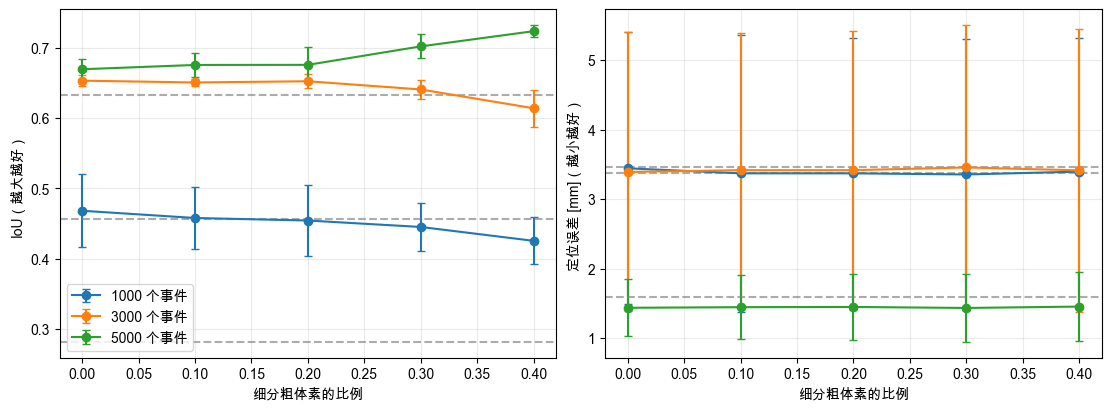

In [103]:
ADAPTIVE_RESULTS_PATH = Path('adaptive_voxel_results/adaptive_voxel_metrics_summary.csv')
FIXED_REFERENCE_PATH = Path('adaptive_voxel_results/adaptive_voxel_fixed_reference.csv')
adaptive_summary = pd.read_csv(ADAPTIVE_RESULTS_PATH)
fixed_reference = pd.read_csv(FIXED_REFERENCE_PATH)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for event_count, group in adaptive_summary.groupby('event_count'):
    axes[0].errorbar(group['refine_fraction'], group['iou_mean'], yerr=group['iou_std'],
                     marker='o', capsize=3, label=f'{event_count} 个事件')
    axes[1].errorbar(group['refine_fraction'], group['localization_error_mm_mean'],
                     yerr=group['localization_error_mm_std'], marker='o', capsize=3,
                     label=f'{event_count} 个事件')
    baseline = fixed_reference[fixed_reference['event_count'] == event_count].iloc[0]
    axes[0].axhline(baseline['iou_mean'], color='gray', linestyle='--', alpha=0.65)
    axes[1].axhline(baseline['localization_error_mm_mean'], color='gray', linestyle='--', alpha=0.65)
axes[0].set(xlabel='细分粗体素的比例', ylabel='IoU（越大越好）')
axes[1].set(xlabel='细分粗体素的比例', ylabel='定位误差 [mm]（越小越好）')
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 18. 当前自适应体素的初步规律

在 1000 和 3000 个事件下，较少细分或不细分的粗体素方案更稳定，说明低统计量时优先保证局部统计可靠性比追求高分辨率更重要。5000 个事件下，随着细分比例增加，IoU 有上升趋势；细分 40% 候选粗体素时 IoU 达到约 `0.723`。

这给出一个可检验的研究假设：**最优细分比例应随事件统计量变化，而不是固定不变。** 但该结果目前只针对理想源和中心 U 型铝目标；下一轮必须改变目标位置和尺寸，确认规则不会只适用于当前场景。

## 19. 偏心目标泛化验证

为了避免算法只依赖“目标在成像中心”的先验，本项目将 U 型铝目标移动至 `(+25, -15) mm`。散射角筛选、截断权重、粗网格和细分规则均保持不变；唯一变化是目标位置。

In [104]:
OFFCENTER_RESULTS_PATH = Path('offcenter_generalization_results/offcenter_metrics_summary.csv')
offcenter_summary = pd.read_csv(OFFCENTER_RESULTS_PATH)
offcenter_summary[['method', 'event_count', 'refine_fraction', 'iou_mean',
                  'localization_error_mm_mean']]

,method,event_count,refine_fraction,iou_mean,localization_error_mm_mean
0,adaptive_16_to_32,1000,0.0,0.454927,7.036823
1,adaptive_16_to_32,1000,0.2,0.413588,7.084393
2,adaptive_16_to_32,1000,0.4,0.373246,7.222547
3,adaptive_16_to_32,3000,0.0,0.692781,3.648128
4,adaptive_16_to_32,3000,0.2,0.675622,3.505510
5,adaptive_16_to_32,3000,0.4,0.625889,3.472529
6,adaptive_16_to_32,5000,0.0,0.745813,1.997556
7,adaptive_16_to_32,5000,0.2,0.741165,1.959570
8,adaptive_16_to_32,5000,0.4,0.727630,1.931299
9,fixed_32x32x32,1000,NaN,0.339862,7.148359


## 20. 偏心验证的解释

偏心 U 型目标仍能被识别，说明方法并非完全依赖目标处于坐标原点。以 5000 个事件为例，固定 32³ 体素 IoU 为约 `0.612`，粗体素自适应方案的 IoU 为约 `0.746`；但细分比例增大时 IoU 不一定继续提高。

这支持“低统计量时优先使用较粗体素，统计量上升后再逐步细分”的研究方向。下一项应验证目标尺寸变化，避免规则只适用于同一个 U 型尺寸。

## 21. 小尺寸目标泛化验证

本轮将 U 型铝目标从 `120 mm × 120 mm` 外轮廓、`30 mm` 壁厚，改为 `80 mm × 80 mm` 外轮廓、`20 mm` 壁厚。重建参数保持不变，因此这是对已有规则的泛化测试，而不是重新为小目标调参。

In [105]:
SMALL_TARGET_RESULTS_PATH = Path('small_target_generalization_results/small_target_metrics_summary.csv')
small_target_summary = pd.read_csv(SMALL_TARGET_RESULTS_PATH)
small_target_summary[['method', 'event_count', 'refine_fraction', 'iou_mean',
                      'localization_error_mm_mean']]

,method,event_count,refine_fraction,iou_mean,localization_error_mm_mean
0,adaptive_16_to_32,1000,0.0,0.436231,5.301258
1,adaptive_16_to_32,1000,0.2,0.397003,5.253651
2,adaptive_16_to_32,1000,0.4,0.353997,5.218763
3,adaptive_16_to_32,3000,0.0,0.535357,3.362319
4,adaptive_16_to_32,3000,0.2,0.524146,3.290446
5,adaptive_16_to_32,3000,0.4,0.537461,3.349422
6,adaptive_16_to_32,5000,0.0,0.552701,2.670637
7,adaptive_16_to_32,5000,0.2,0.545991,2.640815
8,adaptive_16_to_32,5000,0.4,0.582491,2.592106
9,fixed_32x32x32,1000,NaN,0.279700,5.160386


## 22. 尺寸变化后的规律

小尺寸目标在低统计量下更难重建：1000 个入射事件时，固定 32³ 体素 IoU 约为 `0.280`，粗体素方案约为 `0.436`。3000 个事件时，自适应方案仍优于固定体素；但在 5000 个事件下，固定 32³ 体素 IoU 约为 `0.598`，与自适应方案相当或略优。

因此目前得到的更具体结论是：**目标较小或事件数量较少时，较粗的统计单元更有利；目标统计量足够时，固定细体素可能恢复更多边缘细节。** 这正是“统计量驱动自适应分辨率”值得进一步系统化设计的依据。

## 23. 探测器空间分辨率误差验证

这一轮不改变 Geant4 的材料散射，而是在四层探测器击中的 x、y 坐标加入独立高斯误差，然后重新拟合上下游轨迹、计算散射角与 PoCA。这样可以单独研究探测器位置测量误差对成像的影响。

In [106]:
DETECTOR_ERROR_RESULTS_PATH = Path('detector_resolution_results/detector_resolution_metrics_summary.csv')
detector_error_summary = pd.read_csv(DETECTOR_ERROR_RESULTS_PATH)
detector_error_summary[['method', 'event_count', 'position_sigma_mm', 'iou_mean',
                        'localization_error_mm_mean']]

,method,event_count,position_sigma_mm,iou_mean,localization_error_mm_mean
0,adaptive_16_to_32_40pct,1000,0.00,0.421457,4.820773
1,adaptive_16_to_32_40pct,1000,0.05,0.323493,7.321621
2,adaptive_16_to_32_40pct,1000,0.10,0.272337,9.968547
3,adaptive_16_to_32_40pct,1000,0.30,0.225675,12.131067
4,adaptive_16_to_32_40pct,1000,1.00,0.223780,14.839297
5,adaptive_16_to_32_40pct,3000,0.00,0.635711,1.897398
6,adaptive_16_to_32_40pct,3000,0.05,0.468190,3.864681
7,adaptive_16_to_32_40pct,3000,0.10,0.307498,6.637857
8,adaptive_16_to_32_40pct,3000,0.30,0.244373,7.419177
9,adaptive_16_to_32_40pct,3000,1.00,0.211853,7.909185


## 24. 如何理解探测器误差结果

当前四层探测器相邻平面间距约为 100 mm。即使每层只有 `0.05 mm` 的位置误差，也会带来约毫弧度量级的轨迹方向不确定度，与目标散射角处于同一量级，因此 IoU 和定位精度都会下降。以 5000 个事件为例，自适应方案的 IoU 从约 `0.730` 降至约 `0.516`；误差达到 `0.1 mm` 后进一步降至约 `0.349`。

这不是算法失败，而是一个重要的系统设计结论：**探测器空间分辨率、平面间距与低能缪子散射角必须联合考虑。** 后续可研究通过增大同侧两层探测器间距、或在事件权重中加入测量不确定度，来提高误差条件下的鲁棒性。

## 25. 不确定度感知的散射角修正

上一节证明：探测器击中位置存在误差时，观测到的散射角会被放大。若仍直接使用固定 `2 mrad` 阈值，部分本应是测量噪声的事件会被误认为“有效散射”。

本轮保持 PoCA、截断加权和自适应体素流程不变，只在事件筛选前修正散射角。

对于同侧两层探测器间距 `d`、每层 x/y 击中位置独立标准差 `σ`，二维散射角的噪声底近似为：

```text
θ_noise = √8 × σ / d
θ_corrected = √max(θ_observed² − θ_noise², 0)
```

这是一种可解释的近似修正：它不使用 U 型目标真值，只依赖探测器空间分辨率和几何间距。


,method,position_sigma_mm,theta_noise_floor_mrad,selected_events_mean,iou_mean,localization_error_mm_mean
41,固定体素：修正角,0.05,1.414,385.8,0.4762,2.4082
56,固定体素：观测角,0.05,1.414,458.0,0.4621,3.2214
11,自适应体素：修正角,0.05,1.414,385.8,0.5572,2.2889
26,自适应体素：观测角,0.05,1.414,458.0,0.5114,3.2115
42,固定体素：修正角,0.10,2.828,362.0,0.3697,5.9305
57,固定体素：观测角,0.10,2.828,534.0,0.3286,6.7836
12,自适应体素：修正角,0.10,2.828,362.0,0.4000,5.9628
27,自适应体素：观测角,0.10,2.828,534.0,0.3531,6.8273
43,固定体素：修正角,0.30,8.485,303.6,0.2199,9.6800
58,固定体素：观测角,0.30,8.485,506.0,0.2083,8.9441


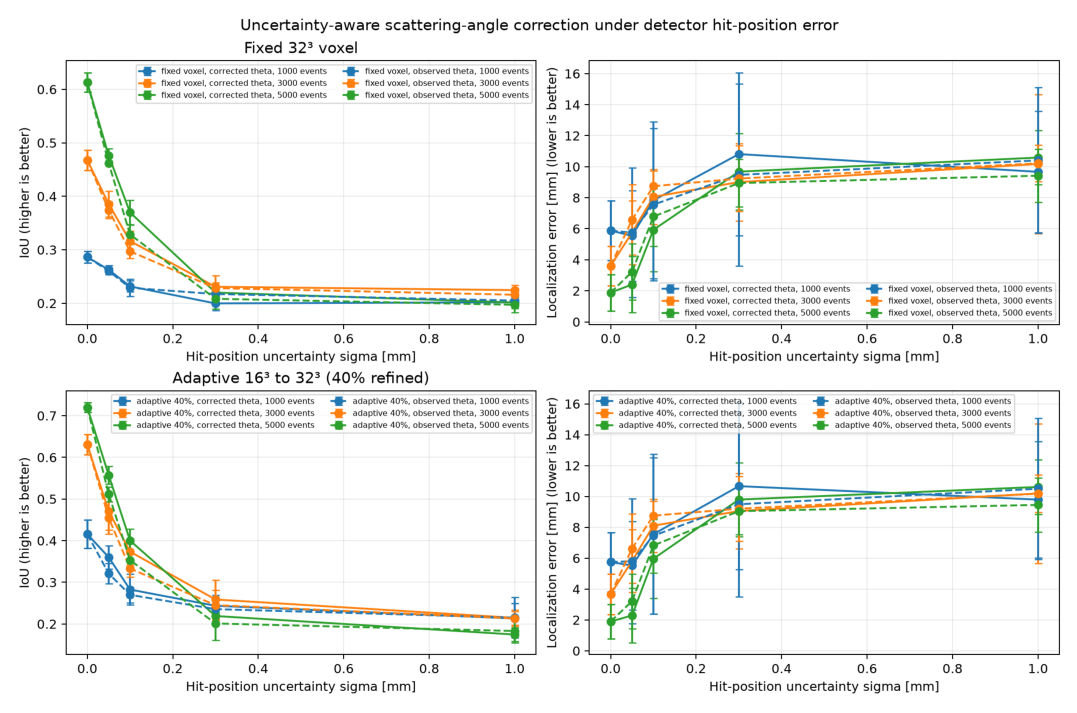

In [108]:
# 读取本轮不确定度修正实验的汇总数据。
# 路径相对于当前 Notebook 所在的 muon_analysis 文件夹。
UNCERTAINTY_RESULTS_PATH = Path('uncertainty_aware_angle_results/uncertainty_aware_metrics_summary.csv')
UNCERTAINTY_FIGURE_PATH = Path('uncertainty_aware_angle_results/uncertainty_aware_angle_metrics.png')

uncertainty_summary = pd.read_csv(UNCERTAINTY_RESULTS_PATH)

# 先聚焦 5000 个事件：这是目前最适合观察算法差异的统计量。
comparison_5000 = uncertainty_summary[
    (uncertainty_summary['event_count'] == 5000)
    & (uncertainty_summary['position_sigma_mm'].isin([0.05, 0.10, 0.30]))
][[
    'method', 'position_sigma_mm', 'theta_noise_floor_mrad',
    'selected_events_mean', 'iou_mean', 'localization_error_mm_mean'
]].copy()

comparison_5000['method'] = comparison_5000['method'].map({
    'fixed_observed': '固定体素：观测角',
    'fixed_corrected': '固定体素：修正角',
    'adaptive40_observed': '自适应体素：观测角',
    'adaptive40_corrected': '自适应体素：修正角',
})
comparison_5000 = comparison_5000.sort_values(['position_sigma_mm', 'method'])

# 不使用 DataFrame.style：部分精简 Python 环境未安装 jinja2，
# 而普通 DataFrame 输出在 VS Code Notebook 中同样清晰、兼容性更好。
display(comparison_5000.round({
    'theta_noise_floor_mrad': 3, 'selected_events_mean': 1,
    'iou_mean': 4, 'localization_error_mm_mean': 4,
}))

# 显示完整的“固定体素 / 自适应体素、观测角 / 修正角”对比图。
# 使用 matplotlib 原生读取，避免依赖额外的 Notebook 显示组件。
figure_image = plt.imread(UNCERTAINTY_FIGURE_PATH)
plt.figure(figsize=(14, 9))
plt.imshow(figure_image)
plt.axis('off')
plt.show()


## 26. 如何解读本轮结果

以 5,000 个事件的自适应体素结果为例：

| 击中位置误差 | 观测角 IoU | 修正角 IoU | 观测角定位误差 | 修正角定位误差 |
|---|---:|---:|---:|---:|
| 0.05 mm | 0.5114 | **0.5572** | 3.2115 mm | **2.2889 mm** |
| 0.10 mm | 0.3531 | **0.4000** | 6.8273 mm | **5.9628 mm** |

因此，在 `0.05–0.10 mm` 的中低误差范围内，修正角减少了被误保留的“假大散射”事件，IoU 和定位精度均有改善。

但当误差升至 `0.30 mm` 以上时，简单的噪声底扣除可能把一部分真实散射也扣掉，定位误差不再稳定改善。这不是失败，而是下一步的明确问题：不能只用“保留 / 删除”的硬阈值，而应让高不确定度事件**降低权重**，而不是被粗暴处理。

下一阶段将实现“不确定度感知的软权重”：让事件贡献同时考虑修正后的散射角和它自身的不确定度。


## 27. 本轮文件与运行方式

- 实验脚本：`run_uncertainty_aware_angle_experiment.py`
- 汇总结果：`uncertainty_aware_angle_results/uncertainty_aware_metrics_summary.csv`
- 结果图：`uncertainty_aware_angle_results/uncertainty_aware_angle_metrics.png`

重新运行实验时，在 `muon_analysis` 文件夹执行：

```bash
MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python run_uncertainty_aware_angle_experiment.py
```

这份 Notebook 负责阅读和解释结果；脚本负责批量重复实验并生成 CSV 与图片。两者功能不同，但应一起维护。


## 28. 不确定度软权重对照实验

上一轮的硬修正通过 `θ_corr = √max(θ_obs²−θ_noise², 0)` 再进行 `2 mrad` 筛选。这里增加一个更温和的对照：沿用**观测角 2 mrad 筛选**，但让不确定度较高的事件少贡献一点散射强度。

```text
θ_noise = √8 × σ / d
q = θ_obs² / (θ_obs² + θ_noise²)
w_soft = min(θ_obs², 3²) × q
```

这里的 `q` 是一个在 0 到 1 之间的启发式可靠度，**不是**严格的事件后验概率。`σ=0` 时 `q=1`，软权重退化为原方法。同一组 5 次抽样和同一组高斯扰动同时用于三种方法，保证对比公平；U 型目标真值只用于最后计算指标。

,position_sigma_mm,method,selected_events_mean,iou_mean,localization_error_mm_mean
11,0.05,hard,385.8,0.5572,2.2889
26,0.05,observed,458.0,0.5114,3.2115
41,0.05,soft,458.0,0.5310,2.8150
12,0.10,hard,362.0,0.4000,5.9628
27,0.10,observed,534.0,0.3531,6.8273
42,0.10,soft,534.0,0.3553,6.2111
13,0.30,hard,303.6,0.2190,9.7964
28,0.30,observed,506.0,0.2011,9.0446
43,0.30,soft,506.0,0.2072,9.2751


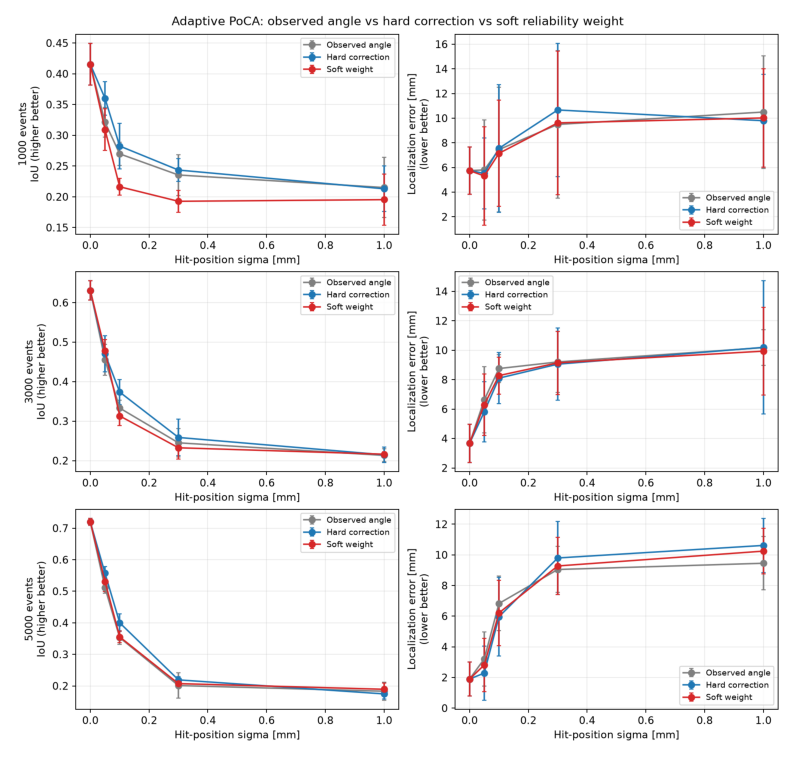

In [109]:
# 从批量实验结果读取三种方法的 5000 事件对照。
# 和前面实验一样，结果文件都保存在 muon_analysis 文件夹下面。
SOFT_RESULTS_PATH = Path('soft_uncertainty_results/soft_uncertainty_metrics_summary.csv')
SOFT_FIGURE_PATH = Path('soft_uncertainty_results/soft_uncertainty_metrics.png')
soft_summary = pd.read_csv(SOFT_RESULTS_PATH)
soft_5000 = soft_summary[
    (soft_summary['event_count'] == 5000)
    & soft_summary['position_sigma_mm'].isin([0.05, 0.10, 0.30])
][['position_sigma_mm', 'method', 'selected_events_mean', 'iou_mean',
   'localization_error_mm_mean']].sort_values(['position_sigma_mm', 'method'])
display(soft_5000.round(4))

# 显示完整图：从上到下分别为 1000、3000、5000 个入射事件；
# 左侧 IoU 越高越好，右侧定位误差越低越好。
plt.figure(figsize=(10, 10))
plt.imshow(plt.imread(SOFT_FIGURE_PATH))
plt.axis('off')
plt.show()


## 29. 怎样理解软权重的结果

以 5,000 个入射事件、自适应体素 40% 细分为例：

| 击中误差 | 方法 | IoU | 定位误差 |
|---|---|---:|---:|
| 0.05 mm | 原观测角 | 0.5114 | 3.2115 mm |
| 0.05 mm | 硬修正 | **0.5572** | **2.2889 mm** |
| 0.05 mm | 软权重 | 0.5310 | 2.8150 mm |
| 0.10 mm | 原观测角 | 0.3531 | 6.8273 mm |
| 0.10 mm | 硬修正 | **0.4000** | **5.9628 mm** |
| 0.10 mm | 软权重 | 0.3553 | 6.2111 mm |
| 0.30 mm | 原观测角 | 0.2011 | **9.0446 mm** |
| 0.30 mm | 硬修正 | **0.2190** | 9.7964 mm |
| 0.30 mm | 软权重 | 0.2072 | 9.2751 mm |

结论：当前软权重在 0.05 mm 条件下比原方法好，但没有超过硬修正；在 0.10 mm 时也没有明显改善 IoU。更大的误差下，所有方法都明显退化。请不要写成“软权重整体优于硬修正”。

为什么可能这样？软方法仍用**观测角**通过 2 mrad 阈值，测量噪声造成的假散射事件仍会进入体素；只降低权重不一定足够。下一步值得研究的是结合轨迹协方差的事件级置信度或软筛选，并考虑 PoCA 位置本身的不确定度。当前结论只是理想入射和此组仿真数据下的初步结果。

可重复运行：`MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python run_soft_uncertainty_weight_experiment.py`。

## 30. 逐事件传播探测器误差

之前用统一的 `θ_noise` 修正角度，但每条缪子的入射、出射方向和两条轨迹的交会关系不同，同样的击中误差可能造成不同的 PoCA 不稳定性。本节用重复拟合直接观察单条事件的波动。

对每条**已经测量到**的四层击中，在每层 x/y 坐标上按已知探测器分辨率 `σ` 生成 `K=12` 组候选击中。每组都重新计算 `θ` 和 PoCA 点。进入重建的每个候选点只拿原事件的 `1/K` 权重，避免将一条缪子错误当作 12 条缪子。

比较四组：原始观测角、之前的硬角度修正、全部候选点传播、传播后“多数通过”筛选。多数通过规则为：至少 6/12 个候选点同时满足 `θ ≥ 2 mrad` 和成像区边界条件。

这相当于一个简化的测量误差传播实验。我们尚未建模探测器对齐误差、非高斯响应、真实宇宙线动量分布，也不能把 12 次抽样直接解释成精确的贝叶斯后验。

,position_sigma_mm,method,iou_mean,iou_std,localization_error_mm_mean,localization_error_mm_std,contributing_unique_events_mean,poca_xy_spread_median_mm
11,0.05,hard,0.5572,0.0217,2.2889,1.7635,385.8,NaN
26,0.05,majority,0.5594,0.0184,2.6809,0.7827,399.8,0.2149
41,0.05,observed,0.5114,0.0173,3.2115,1.7634,458.0,NaN
56,0.05,propagated,0.4925,0.0134,4.3358,1.4309,1467.0,0.2149
12,0.10,hard,0.4000,0.0278,5.9628,2.5630,362.0,NaN
27,0.10,majority,0.3902,0.0209,4.3092,3.3666,345.2,0.4247
42,0.10,observed,0.3531,0.0217,6.8273,1.7834,534.0,NaN
57,0.10,propagated,0.3131,0.0206,7.1228,1.4342,1676.2,0.4247
13,0.30,hard,0.2190,0.0097,9.7964,2.3825,303.6,NaN
28,0.30,majority,0.2110,0.0187,10.7899,2.2712,254.0,1.2215


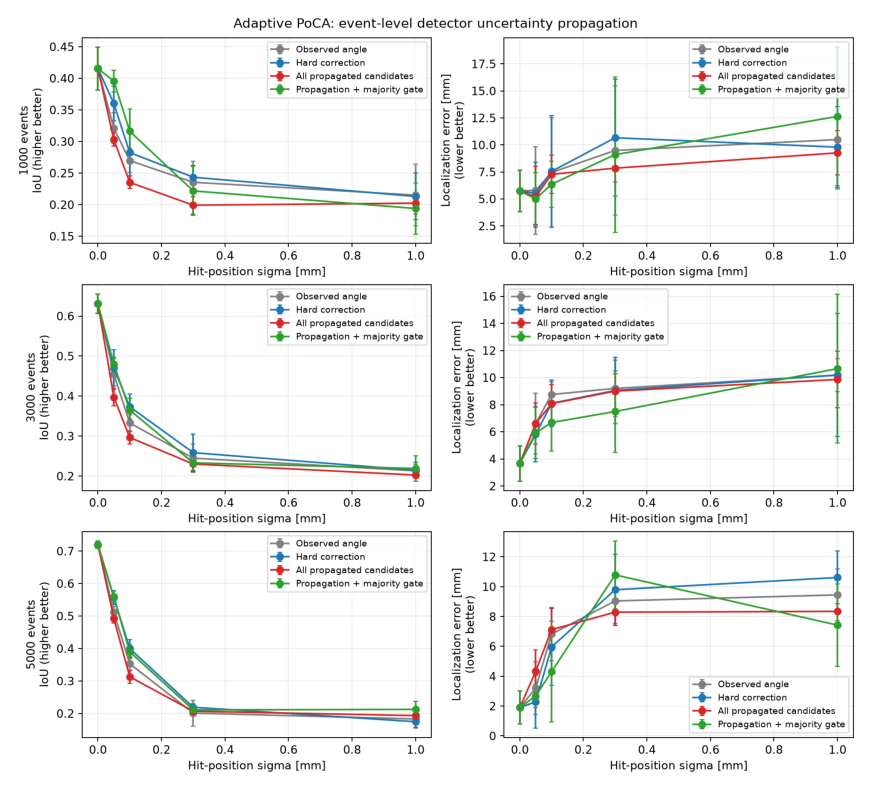

In [110]:
# 查看逐事件误差传播的汇总结果。
# 普通 DataFrame 输出兼容不含 jinja2 的 Notebook 环境。
EVENT_UNCERTAINTY_PATH = Path('event_uncertainty_results/event_uncertainty_metrics_summary.csv')
EVENT_UNCERTAINTY_FIGURE = Path('event_uncertainty_results/event_uncertainty_metrics.png')
event_uncertainty_summary = pd.read_csv(EVENT_UNCERTAINTY_PATH)
comparison = event_uncertainty_summary[
    (event_uncertainty_summary['event_count'] == 5000)
    & event_uncertainty_summary['position_sigma_mm'].isin([0.05, 0.10, 0.30])
][[
    'position_sigma_mm', 'method', 'iou_mean', 'iou_std',
    'localization_error_mm_mean', 'localization_error_mm_std',
    'contributing_unique_events_mean', 'poca_xy_spread_median_mm'
]].sort_values(['position_sigma_mm', 'method'])
display(comparison.round(4))

# 三行依次为 1000、3000、5000 事件；左侧 IoU 越高越好，右侧定位误差越低越好。
plt.figure(figsize=(11, 10))
plt.imshow(plt.imread(EVENT_UNCERTAINTY_FIGURE))
plt.axis('off')
plt.show()


## 31. 结果说明与下一步

5,000 个入射事件时：

| 击中误差 | 方法 | IoU | 定位误差 |
|---|---|---:|---:|
| 0.05 mm | 原方法 | 0.5114 | 3.2115 mm |
| 0.05 mm | 硬修正 | 0.5572 | **2.2889 mm** |
| 0.05 mm | 全部候选点传播 | 0.4925 | 4.3358 mm |
| 0.05 mm | 多数通过传播 | **0.5594** | 2.6809 mm |
| 0.10 mm | 原方法 | 0.3531 | 6.8273 mm |
| 0.10 mm | 硬修正 | **0.4000** | 5.9628 mm |
| 0.10 mm | 多数通过传播 | 0.3902 | **4.3092 mm** |
| 0.30 mm | 原方法 | 0.2011 | **9.0446 mm** |
| 0.30 mm | 硬修正 | **0.2190** | 9.7964 mm |
| 0.30 mm | 多数通过传播 | 0.2110 | 10.7899 mm |

多数通过规则在 0.05–0.10 mm 有一定价值，但没有稳定超过硬修正；尤其 `0.10 mm` 定位误差的重复波动较大。高误差下仍明显退化。全部候选点传播效果更差，提示**位置不确定度需要结合事件质量筛选**，不能把每个随机候选点都作为可信信号。

`contributing_unique_events_mean` 是真正有贡献的原始缪子条数；候选点虽然更多，却没有增加真实统计量。`poca_xy_spread_median_mm` 只在通过筛选的候选点之间计算，所以可能低估所有候选位置的总不确定度。

下一步应验证不同目标位置/尺寸和更真实的入射条件，并考虑对候选概率做校准；不应根据本图单独宣称一种方法在所有误差条件下更优。

重新运行批量脚本：`MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python run_event_uncertainty_experiment.py`。

## 32. 不确定度方法的跨场景验证

前面的误差传播实验只针对中心大 U 型目标。为检查算法是否记住某个位置或尺寸，本轮把**完全相同的参数**直接用于三种独立 Geant4 场景：

1. 中心大 U 型目标；
2. 偏心大 U 型目标，中心移动到 `(25, −15) mm`；
3. 小尺寸 U 型目标，外轮廓 `80×80 mm`，壁厚 `20 mm`。

每个场景使用 `1000/3000/5000` 个事件，探测器击中位置误差 `0/0.05/0.10/0.30 mm`，每种组合重复 5 次。散射角阈值 `2 mrad`、权重上限 `3 mrad`、自适应细分比例 `40%`、每事件候选数 `12` 和多数通过门槛 `6/12` 均固定。目标真值只用于结果评价。

,scenario,method,iou_mean,iou_std,localization_error_mm_mean,localization_error_mm_std
10,center,hard,0.4000,0.0278,5.9628,2.5630
22,center,majority,0.3902,0.0209,4.3092,3.3666
34,center,observed,0.3531,0.0217,6.8273,1.7834
46,center,propagated,0.3131,0.0206,7.1228,1.4342
58,offcenter,hard,0.3863,0.0229,18.1478,2.4847
70,offcenter,majority,0.3395,0.0268,19.2512,2.3336
82,offcenter,observed,0.3070,0.0229,25.6511,1.7291
94,offcenter,propagated,0.2676,0.0185,29.3825,1.6208
106,small,hard,0.2003,0.0208,5.8921,2.6973
118,small,majority,0.2324,0.0375,5.5869,3.6380


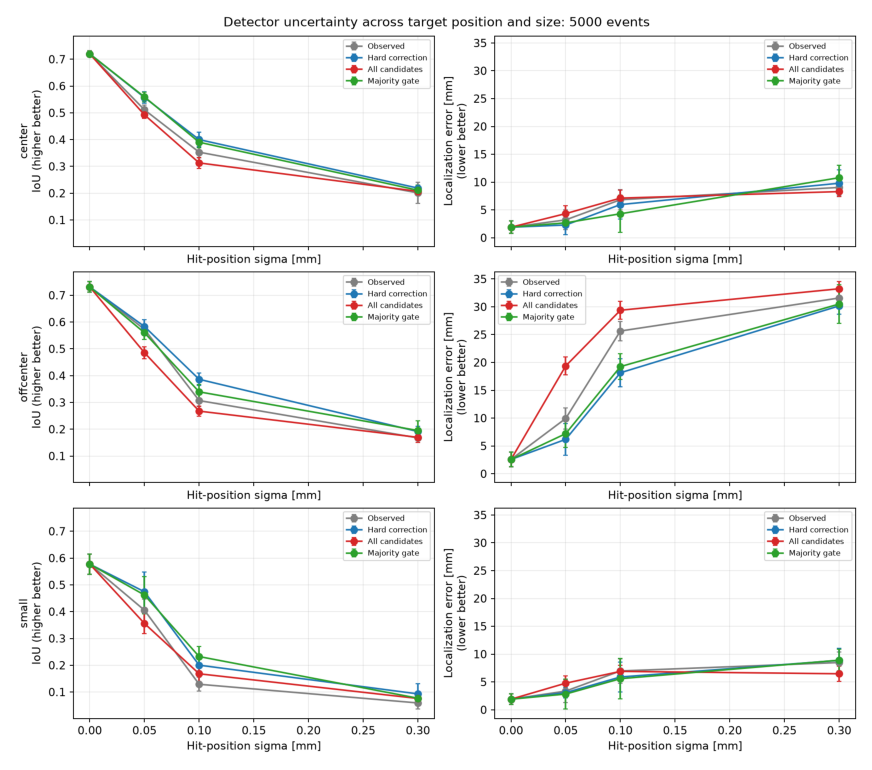

In [111]:
# 汇总表中的指标已经按 5 次重复计算均值和标准差。
CROSS_SCENARIO_RESULTS = Path('uncertainty_cross_scenario_results/uncertainty_cross_scenario_summary.csv')
CROSS_SCENARIO_FIGURE = Path('uncertainty_cross_scenario_results/uncertainty_cross_scenario_5000.png')
cross_scenario = pd.read_csv(CROSS_SCENARIO_RESULTS)

# 先看 5000 事件、0.10 mm 误差时，三种几何场景中的方法排序。
display(cross_scenario[
    (cross_scenario['event_count'] == 5000)
    & (cross_scenario['position_sigma_mm'] == 0.10)
][[
    'scenario', 'method', 'iou_mean', 'iou_std',
    'localization_error_mm_mean', 'localization_error_mm_std'
]].sort_values(['scenario', 'method']).round(4))

# 三行分别是中心大 U、偏心大 U 和小 U；左 IoU 越高越好，右定位误差越低越好。
plt.figure(figsize=(11, 10))
plt.imshow(plt.imread(CROSS_SCENARIO_FIGURE))
plt.axis('off')
plt.show()


## 33. 跨场景结果怎样理解

以 `5000` 个入射事件、`0.10 mm` 击中误差为例：

| 场景 | 原方法 IoU | 硬修正 IoU | 多数通过 IoU | 主要现象 |
|---|---:|---:|---:|---|
| 中心大 U | 0.353 | **0.400** | 0.390 | 两种改进都有帮助 |
| 偏心大 U | 0.307 | **0.386** | 0.339 | 硬修正更稳，定位仍明显偏移 |
| 小 U | 0.129 | 0.200 | **0.232** | 多数通过的轮廓更接近真值 |

偏心目标在 `0.10 mm` 时，硬修正的定位误差约 `18.15 mm`，多数通过约 `19.25 mm`；尽管比原方法约 `25.65 mm` 好，仍远高于零误差时约 `2.57 mm`。这说明非理想探测器下不能只看 IoU，也必须检查目标定位。

小目标下多数通过的 IoU 有优势，但它与硬修正的定位误差差异较小，而且每组目前只有 5 次重复。`0.30 mm` 时三种场景普遍严重退化。因此**还不能宣称多数通过规则全面优于硬修正**。

大量候选点直接累积通常更差；这一负结果说明不确定度传播必须配合事件质量判断。更值得进一步研究的是：怎样使筛选门槛随探测器分辨率、目标尺度和局部统计量自动变化，并在自然入射条件下验证。

批量重现实验：`MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python run_uncertainty_cross_scenario.py`。

## 34. 偏心目标的定位偏差从哪里来

上一轮看到：偏心 U 型目标的 IoU 仍有改善，但全图散射强度质心在探测器误差下偏移很大。要解释原因，先把图像强度分成真实目标区域内和外两部分（**只在事后诊断时使用目标真值**）：

```text
全图质心 = f × 区域内质心 + (1−f) × 区域外质心
f = 目标区域内图像权重 / 全图图像权重
```

如果区域内质心仍靠近真实位置，但 `f` 下降，且区域外质心接近成像区域中心，**全图质心**就会被背景拉向中心。偏心目标对此格外敏感。下面读取 5 次重复的定量诊断结果。

,position_sigma_mm,true_x_mm_mean,true_y_mm_mean,reconstructed_x_mm_mean,reconstructed_y_mm_mean,inside_centroid_x_mm_mean,inside_centroid_y_mm_mean,target_region_weight_fraction_mean,localization_error_mm_mean,background_corrected_error_mm_mean
0,0.00,25.3125,-23.4021,26.7169,-24.6754,25.3894,-23.1701,0.8793,2.5739,5.7284
1,0.05,25.3125,-23.4021,21.4265,-18.6514,24.6902,-21.8348,0.7442,6.1860,5.1278
2,0.10,25.3125,-23.4021,12.1847,-10.9642,23.8483,-21.7792,0.5310,18.1478,21.5098
3,0.30,25.3125,-23.4021,3.2568,-2.9226,26.4894,-21.7488,0.3195,30.1619,43.1959


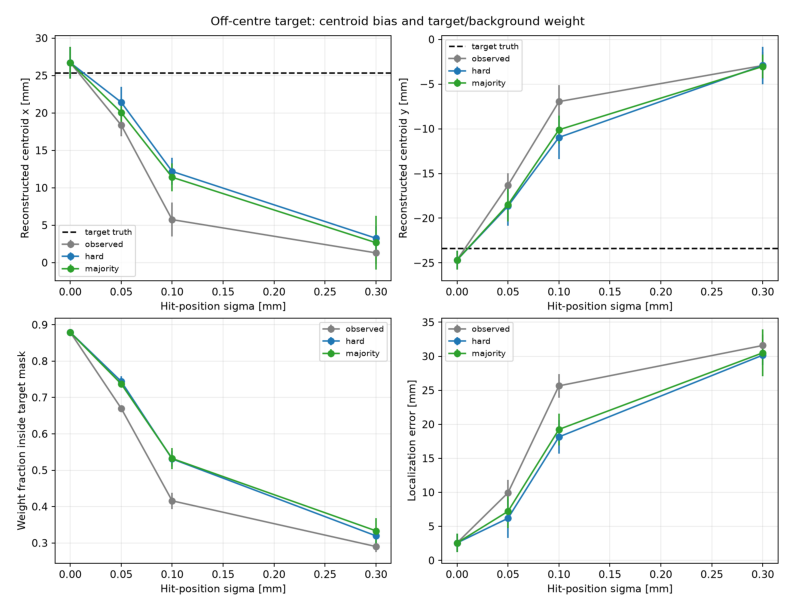

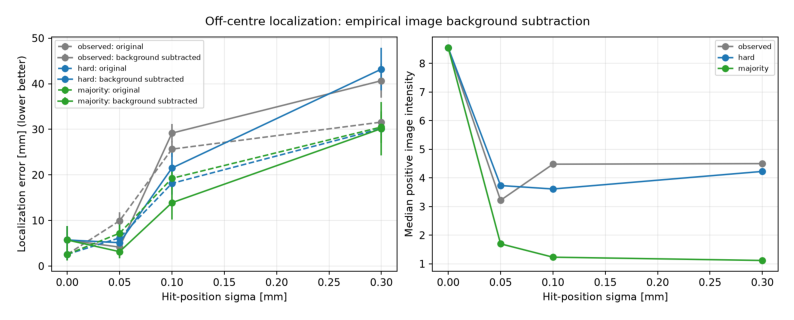

In [112]:
# 只读取诊断脚本写出的 CSV；不使用目标真值来重新计算任何重建图。
OFFCENTER_DIAG_DIR = Path('offcenter_localization_diagnosis')
offcenter_diag = pd.read_csv(OFFCENTER_DIAG_DIR / 'offcenter_centroid_summary.csv')
display(offcenter_diag[
    (offcenter_diag['method'] == 'hard')
    & offcenter_diag['position_sigma_mm'].isin([0.0, 0.05, 0.10, 0.30])
][[
    'position_sigma_mm', 'true_x_mm_mean', 'true_y_mm_mean',
    'reconstructed_x_mm_mean', 'reconstructed_y_mm_mean',
    'inside_centroid_x_mm_mean', 'inside_centroid_y_mm_mean',
    'target_region_weight_fraction_mean', 'localization_error_mm_mean',
    'background_corrected_error_mm_mean'
]].round(4))

# 图一：全图质心 x/y 如何移动，以及目标区域内的权重占比如何下降。
plt.figure(figsize=(10, 8))
plt.imshow(plt.imread(OFFCENTER_DIAG_DIR / 'offcenter_centroid_diagnosis.png'))
plt.axis('off')
plt.show()

# 图二：不依赖目标真值的“图像背景中位数扣除”尝试。
plt.figure(figsize=(10, 4))
plt.imshow(plt.imread(OFFCENTER_DIAG_DIR / 'offcenter_background_subtraction.png'))
plt.axis('off')
plt.show()


## 35. 诊断结论与失败的简单修正

以 5,000 事件、硬修正方法为例，真值 U 掩膜的离散质心约为 `(25.31, −23.40) mm`：

| 击中误差 | 区域内权重占比 | 目标区域内质心 | 全图质心 | 全图定位误差 |
|---|---:|---|---|---:|
| 0 mm | 0.879 | (25.39, −23.17) mm | (26.72, −24.68) mm | 2.57 mm |
| 0.10 mm | 0.531 | (23.85, −21.78) mm | (12.18, −10.96) mm | 18.15 mm |
| 0.30 mm | 0.319 | (26.49, −21.75) mm | (3.26, −2.92) mm | 30.16 mm |

这里“区域内质心”**只用于诊断机制**，不能拿它作为可部署的定位结果，因为实际成像时不知道目标真值。大量背景权重逐渐把全图质心拉向成像区中央，是当前偏心定位失效的主要表现。

试验了一个不使用目标真值的简单修正：从每个像素强度中扣除该图非零像素强度的中位数，再计算质心。它没有稳定改善：硬修正在 `0.10 mm` 时误差从 `18.15 mm` 反增至 `21.51 mm`。这说明背景并非可以靠一个全图常数消除，目标信号也会一并被减弱。

下一步应研究无需真值的**局部目标区域估计**，再在独立目标位置、尺寸与探测器误差上验证；不要只在偏心 U 上选一个最优阈值。

重现实验：`MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python diagnose_offcenter_localization.py`。

## 36. 不用真值估计局部目标位置

上节发现背景强度会把偏心目标的**全图质心**拉向成像区域中央。本节测试两种只读取重建图像的局部化规则：

1. **高散射连通区域**：3×3 平滑后选最高强度的 15% 像素，找到总强度最大的连通区域并求中心。
2. **固定尺度滑动窗口**：在全图移动 24×24 像素窗口，选累计散射强度最大的窗口，再求窗口内的强度质心。

目标真值只用于计算定位误差，不参与这两种规则。固定窗口约覆盖 135 mm，含有“目标不会超过该尺度”的先验，因此它并不适合直接推广到完全未知尺度的目标。所有参数均同时用于中心、偏心和小尺寸三种场景。

In [ ]:
# 读取三场景、三个事件数、四种探测器误差的五次重复结果。
LOCAL_REGION_DIR = Path('local_region_results')
local_region_results = pd.read_csv(LOCAL_REGION_DIR / 'local_region_summary.csv')

# 先比较 5000 个事件、0.10 mm 误差、硬修正后的三种定位方式。
display(local_region_results[
    (local_region_results['event_count'] == 5000)
    & (local_region_results['position_sigma_mm'] == 0.10)
    & (local_region_results['method'] == 'hard')
][[
    'scenario', 'global_error_mm_mean', 'local_error_mm_mean',
    'window_error_mm_mean', 'component_pixels_mean'
]].round(3))

# 展示完整的滑动窗口对照图；虚线是全图质心，实线是局部窗口质心。
plt.figure(figsize=(10, 9))
plt.imshow(plt.imread(LOCAL_REGION_DIR / 'sliding_window_vs_global_5000.png'))
plt.axis('off')
plt.show()


## 37. 局部定位的收益与尺度问题

以 `5000` 事件、`0.10 mm` 击中误差、硬修正后的图像为例：

| 目标场景 | 全图质心误差 | 连通区域误差 | 24×24 窗口误差 |
|---|---:|---:|---:|
| 中心大 U | 5.96 mm | 45.61 mm | 5.88 mm |
| 偏心大 U | 18.15 mm | 40.76 mm | **4.85 mm** |
| 小 U | **5.89 mm** | 28.24 mm | 19.07 mm |

**解释：**高散射连通区域常只选择 U 型的一条臂，因此不能把连通热点直接当作整个目标中心。较大的滑动窗口能够覆盖偏心大 U 的两条臂和底部，减轻背景拉偏；但是同样窗口对于小 U 太大，重新混入很多背景，表现变差。`0.30 mm` 高误差时，大窗口也会令中心和小 U 的定位进一步退化。

因此当前窗口法只是一个**探索性局部定位基线**，并非已经验证的通用改进。接下来应当根据图像中的局部统计量选择窗口尺度，并在未参与规则设计的新目标位置、尺寸与材料组合上验证，避免按照本轮结果反向调参。

重新运行：`MPLCONFIGDIR=../B1/.matplotlib-cache ../B1/.venv/bin/python run_local_region_validation.py`。

## 38. 自动选择定位窗口：规则与独立验证

前一节看到固定 24×24 窗口能缓解偏心大 U 型目标的背景偏移，但在 80 mm 小 U 型目标上会包含过多背景。因此本轮尝试**仅从重建图**在 14、18、24 像素三个尺度中选窗口。

对每个候选窗口计算：`(窗口平均散射强度 - 全图平均散射强度) × 窗口边长`。使用 3×3 平滑图选择窗口，最后仍在原始图上计算窗口内强度质心。目标真值只用于最后计算定位误差，**没有进入选窗口公式**。

先固定上述规则，再用新 Geant4 场景 `medium_offset` 独立验证：U 型铝块外宽 100 mm、壁厚 25 mm、中心 (-20, +15) mm；这与之前三个场景均不同。所有对比统一采用 40% 自适应体素 + hard 散射角修正、相同事件子样本和噪声。这里的误差为重建图估计中心与离散化目标掩膜中心的二维距离；不等同于材料识别正确率。


In [113]:
# 只读取已经生成的实验数据；运行本单元不会重新执行 Geant4。
MULTISCALE_DIR = Path('multiscale_localization_results')
dev = pd.read_csv(MULTISCALE_DIR / 'multiscale_summary_center_offcenter_small.csv')
heldout = pd.read_csv(MULTISCALE_DIR / 'multiscale_summary_medium_offset.csv')
multiscale_summary = pd.concat([dev, heldout], ignore_index=True)

# 先看 5000 事件的三个对照：全图质心、固定 24 窗口、图像自动选尺度。
display(multiscale_summary[multiscale_summary['event_count'] == 5000][[
    'scenario', 'position_sigma_mm', 'global_error_mm_mean',
    'fixed24_error_mm_mean', 'multiscale_error_mm_mean',
    'selected_window_bins_mean'
]].round(2))


,scenario,position_sigma_mm,global_error_mm_mean,fixed24_error_mm_mean,multiscale_error_mm_mean,selected_window_bins_mean
8,center,0.00,1.90,1.87,5.75,21.6
9,center,0.05,2.29,2.11,8.06,20.4
10,center,0.10,5.96,5.88,5.55,21.6
11,center,0.30,9.80,22.10,48.62,14.8
20,offcenter,0.00,2.57,2.86,8.65,21.6
21,offcenter,0.05,6.19,2.86,10.00,20.4
22,offcenter,0.10,18.15,4.85,10.23,20.4
23,offcenter,0.30,30.16,11.78,16.09,17.6
32,small,0.00,1.90,1.99,4.04,14.0
33,small,0.05,3.07,8.53,5.14,14.0


## 39. 读图：什么时候自动选尺度有效？

5000 事件、`sigma=0.10 mm`：小 U 型的自动法为约 **6.10 mm**，固定 24 窗口为 **19.07 mm**；偏心大 U 型却是 **10.23 mm** 对 **4.85 mm**。在独立的中等尺寸偏心场景，自动法约 **5.91 mm**，固定 24 为 **9.57 mm**，说明它有一定跨尺寸价值，但并非普遍占优。

更关键的是 `sigma=0.30 mm`：独立场景自动法约 **46.10 mm**，比全图质心 **21.27 mm**、固定 24 窗口 **23.55 mm** 都差。大噪声下局部热点可能夺得最高评分，导致窗口跑向错误区域。因此这一步应记录为**有条件的改进与明确的失败边界**，不能写成“算法整体优于基线”。下一步可以考虑基于空间连贯性和跨尺度一致性的约束，但必须再用新的未参与设计场景验证。


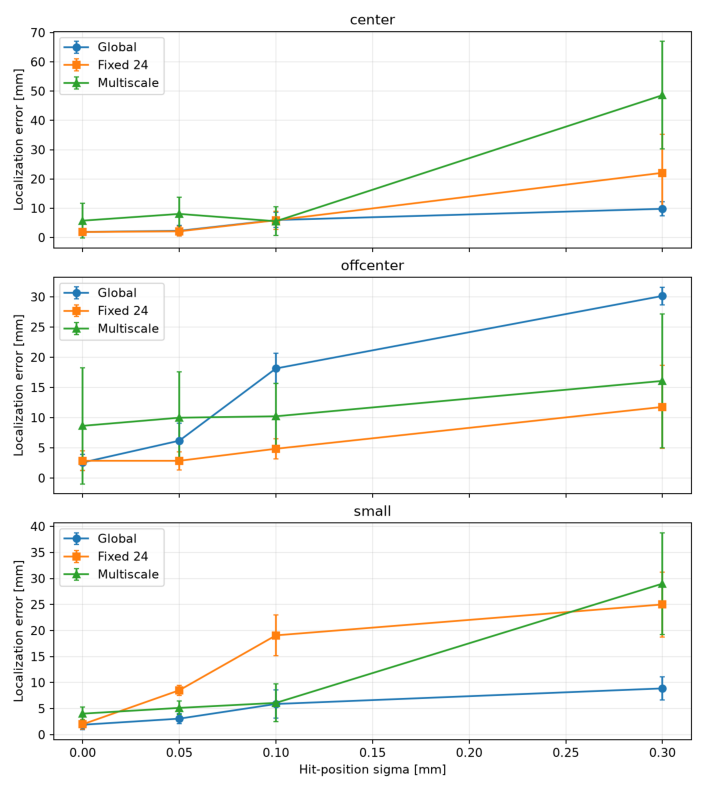

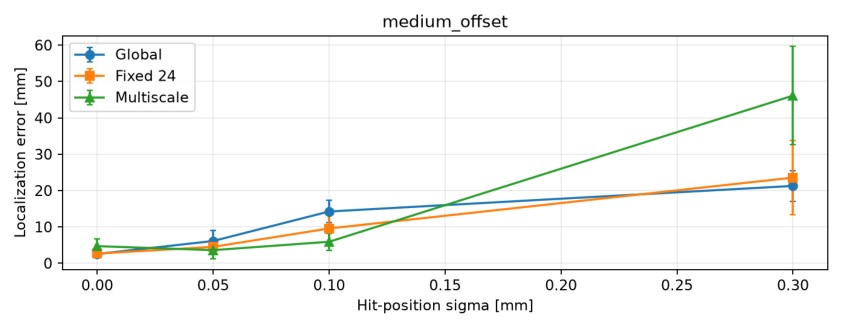

,position_sigma_mm,repeat,selected_window_bins,global_error_mm,fixed24_error_mm,multiscale_error_mm
40,0.00,1,18,2.99,2.68,4.85
41,0.05,1,18,7.42,3.46,2.83
42,0.10,1,18,15.85,9.52,3.93
43,0.30,1,14,23.68,32.48,50.60
44,0.00,2,18,3.07,3.40,7.96
45,0.05,2,18,2.21,5.40,0.89
46,0.10,2,18,11.12,10.08,9.12
47,0.30,2,14,23.13,34.15,59.21
48,0.00,3,18,1.53,1.59,2.33
49,0.05,3,18,6.27,1.79,3.43


In [114]:
# 观察旧场景与独立验证场景的曲线。误差棒代表 5 次重复的标准差。
for figure_name in (
    'multiscale_comparison_center_offcenter_small.png',
    'multiscale_comparison_medium_offset.png',
):
    plt.figure(figsize=(11, 10 if 'center_offcenter_small' in figure_name else 4))
    plt.imshow(plt.imread(MULTISCALE_DIR / figure_name))
    plt.axis('off')
    plt.show()

# 逐次重复结果还能用于检查“平均值”是否被少数严重失误拉高。
heldout_repeats = pd.read_csv(
    MULTISCALE_DIR / 'multiscale_by_repeat_medium_offset.csv'
)
display(heldout_repeats[heldout_repeats['event_count'] == 5000][[
    'position_sigma_mm', 'repeat', 'selected_window_bins',
    'global_error_mm', 'fixed24_error_mm', 'multiscale_error_mm'
]].round(2))


## 40. 最亮像素截断：抗热点尝试

上一轮多尺度窗口在 `sigma=0.30 mm` 时常被背景中的假热点带偏。这次只增加一个步骤：将每张图所有**正强度像素**高于其 95% 分位数的强度压到该分位数，再沿用原来的 14/18/24 像素窗口评分。这叫“强度截断”或 winsorization；它不需要目标真值。

对照方法仍然是全图质心、固定 24 窗口、原多尺度法。四种方法对同一张 PoCA 图计算，因此事件子样本和噪声完全相同。先在之前的四个场景上验证，再对新的 `small_offset` 场景做独立测试：外宽 80 mm、壁厚 20 mm、中心 `(30, 20) mm`。**新场景没有用于设定 95% 截断规则。**

注意：这是抗热点的简单对照实验，不是已经证实有效的最终算法。


In [116]:
# 下面只读取实验生成的 CSV，不重新运行 Geant4。
ROBUST_DIR = Path('robust_localization_results')
robust_dev = pd.read_csv(
    ROBUST_DIR / 'robust_summary_center_offcenter_small_medium_offset.csv'
)
robust_holdout = pd.read_csv(ROBUST_DIR / 'robust_summary_small_offset.csv')
robust_summary = pd.concat([robust_dev, robust_holdout], ignore_index=True)

# 聚焦 5000 事件；每项是 5 次重复的平均二维定位误差，单位 mm。
display(robust_summary[robust_summary['event_count'] == 5000][[
    'scenario', 'position_sigma_mm', 'global_error_mm_mean',
    'fixed24_error_mm_mean', 'multiscale_error_mm_mean',
    'robust_error_mm_mean', 'robust_window_bins_mean'
]].round(2))


,scenario,position_sigma_mm,global_error_mm_mean,fixed24_error_mm_mean,multiscale_error_mm_mean,robust_error_mm_mean,robust_window_bins_mean
8,center,0.00,1.90,1.87,5.75,5.64,21.6
9,center,0.05,2.29,2.11,8.06,8.64,20.4
10,center,0.10,5.96,5.88,5.55,5.90,21.6
11,center,0.30,9.80,22.10,48.62,43.14,15.6
20,medium_offset,0.00,2.55,2.66,4.71,4.74,18.0
21,medium_offset,0.05,6.12,4.52,3.61,3.63,18.0
22,medium_offset,0.10,14.24,9.57,5.91,4.86,18.0
23,medium_offset,0.30,21.27,23.55,46.10,59.77,14.0
32,offcenter,0.00,2.57,2.86,8.65,4.93,22.8
33,offcenter,0.05,6.19,2.86,10.00,7.45,21.6


## 41. 独立验证结果与研究决定

新偏心小目标、5000 事件下：`sigma=0.10 mm` 时，原多尺度 **4.63 mm**，截断后反而 **6.76 mm**；`sigma=0.30 mm` 时，原多尺度 **45.20 mm**，截断后降至 **31.66 mm**，但仍不如固定窗口 **23.13 mm**。另外四个既有场景在高噪声下也没有一致改善。误差棒较大，表明不同事件子样本之间波动明显。

结论：单纯压低少数亮像素**不能稳定解决高噪声定位问题**。本方法保留为失败对照，不作为论文的主创新。下一步应检查高噪声假热点究竟来自孤立大权重事件，还是空间上分散的系统性背景；再考虑跨尺度位置一致性或事件可靠性，而不是继续盲目调截断分位数。


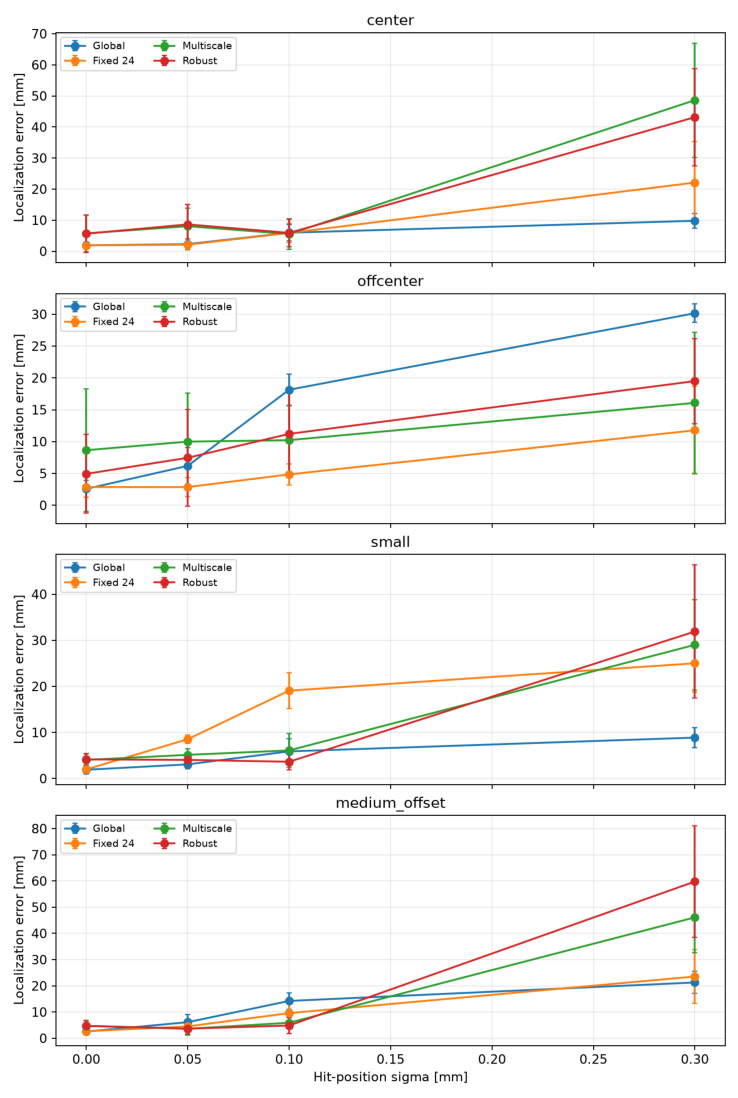

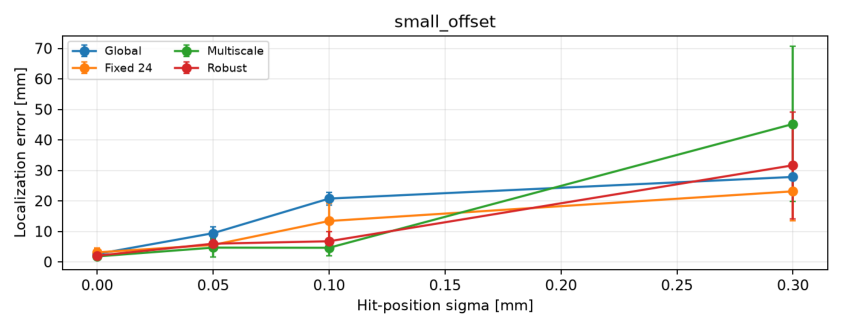

,repeat,fixed24_error_mm,multiscale_error_mm,robust_error_mm,robust_window_bins
43,1,14.89,20.81,20.87,18
47,2,32.02,62.35,47.31,14
51,3,15.32,16.10,16.76,14
55,4,18.37,53.62,53.87,18
59,5,35.02,73.11,19.50,18


In [117]:
# 两张图分别展示旧场景与完全新场景。纵轴越低越好。
for figure_name in (
    'robust_comparison_center_offcenter_small_medium_offset.png',
    'robust_comparison_small_offset.png',
):
    plt.figure(figsize=(11, 14 if 'center_offcenter_small' in figure_name else 4))
    plt.imshow(plt.imread(ROBUST_DIR / figure_name))
    plt.axis('off')
    plt.show()

# 看新场景高噪声下每一次重复的结果，避免只看平均值。
holdout_repeats = pd.read_csv(ROBUST_DIR / 'robust_by_repeat_small_offset.csv')
display(holdout_repeats[
    (holdout_repeats['event_count'] == 5000)
    & (holdout_repeats['position_sigma_mm'] == 0.30)
][[
    'repeat', 'fixed24_error_mm', 'multiscale_error_mm',
    'robust_error_mm', 'robust_window_bins'
]].round(2))


## 42. 高噪声下自动定位为什么失败？

上一节证明“压低最亮像素”并不能稳定救回定位。这次**不改算法**，只在事后诊断失败来源：同一组 5000 事件在 `sigma=0 / 0.10 / 0.30 mm` 下重建，五个 U 型场景各重复 5 次。

同时观察四类量：①目标掩膜内的图像权重占比；②目标外有信号像素的比例；③目标外最亮 5% 的**正强度**像素占目标外权重的比例；④单个事件、最重 5% 事件的权重占比。前两项量化“信号是否变成广泛背景”，后两项检查“是否只由少数极亮点主导”。真值只用于事后内外划分，不参与 PoCA、筛选或自动窗口选择。


In [118]:
# 已生成的配对诊断结果：只读取 CSV，不重新运行仿真。
HOTSPOT_DIR = Path('hotspot_diagnosis_results')
hotspot_summary = pd.read_csv(HOTSPOT_DIR / 'hotspot_diagnosis_summary.csv')

# 先看没有噪声和较高噪声的变化。背景最亮 5% 占比越高，越像少数热点主导。
display(hotspot_summary[
    hotspot_summary['position_sigma_mm'].isin([0.0, 0.30])
][[
    'scenario', 'position_sigma_mm',
    'selected_events_mean', 'event_max_weight_fraction_mean',
    'event_target_weight_fraction_mean', 'target_image_weight_fraction_mean',
    'background_occupied_fraction_mean',
    'background_top5_pixel_weight_fraction_mean',
    'auto_error_mm_mean'
]].round(3))


,scenario,position_sigma_mm,selected_events_mean,event_max_weight_fraction_mean,event_target_weight_fraction_mean,target_image_weight_fraction_mean,background_occupied_fraction_mean,background_top5_pixel_weight_fraction_mean,auto_error_mm_mean
0,center,0.0,406.8,0.003,0.992,0.925,0.120,0.144,5.752
2,center,0.3,303.6,0.003,0.364,0.355,0.524,0.171,48.616
3,medium_offset,0.0,265.6,0.004,0.880,0.840,0.113,0.209,4.708
5,medium_offset,0.3,285.6,0.004,0.213,0.212,0.479,0.161,46.103
6,offcenter,0.0,407.8,0.003,0.914,0.879,0.139,0.212,8.649
8,offcenter,0.3,307.4,0.003,0.315,0.319,0.512,0.160,16.086
9,small,0.0,182.6,0.006,0.827,0.735,0.094,0.201,4.038
11,small,0.3,274.0,0.004,0.126,0.122,0.515,0.154,29.004
12,small_offset,0.0,192.4,0.006,0.919,0.874,0.057,0.201,1.800
14,small_offset,0.3,283.2,0.004,0.179,0.171,0.469,0.161,45.199


## 43. 诊断结论：大范围背景比单点热点更关键

独立的 `small_offset` 场景从 `sigma=0` 增至 `0.30 mm` 时：图像权重落在目标内的比例约 **0.874 → 0.171**；目标外有信号像素占比约 **0.057 → 0.469**。相反，目标外最亮 5% 正像素的权重份额约 **0.201 → 0.161**，并没有集中到少数最亮像素；单个事件权重份额也始终不足约 1%。另外四个目标场景呈类似趋势。

这说明此次**仿真条件与现有角度截断规则下**的主要问题是目标信号向较宽的伪背景扩散，而不是单个超大权重事件。下图第 5 次重复展示同一批事件：白色是目标真值（仅用作解释），蓝色是无真值自动窗口。`sigma=0.30 mm` 时窗口转向左下方背景，定位误差达到约 **73.1 mm**；这只是一个失败示例，所有重复的平均结果应看上表。

下一步优先检查 **PoCA 位置不确定度和事件通过角度筛选后的组成**，再设计事件可靠性或体素置信度约束。现在不应继续仅靠调节图像亮度截断阈值。


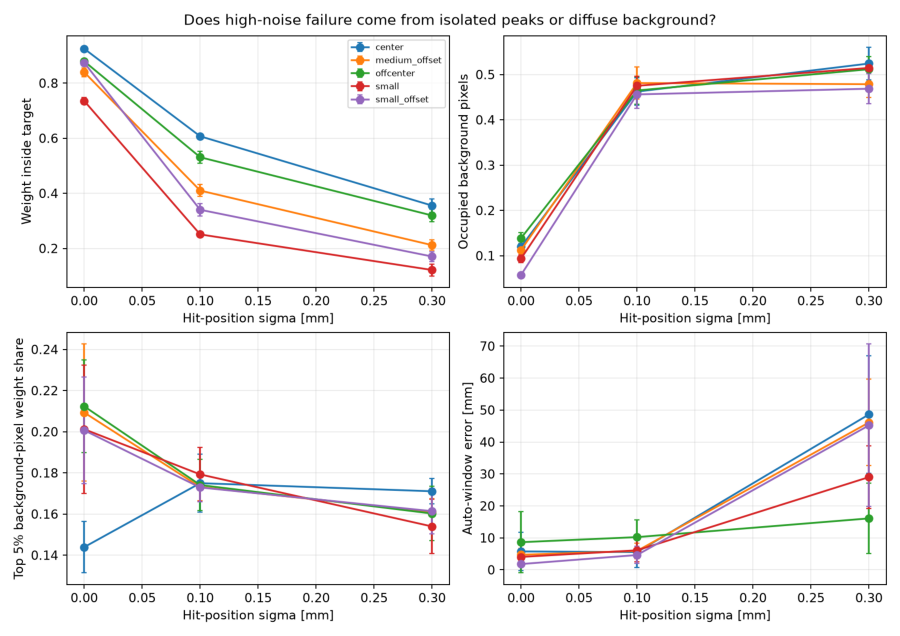

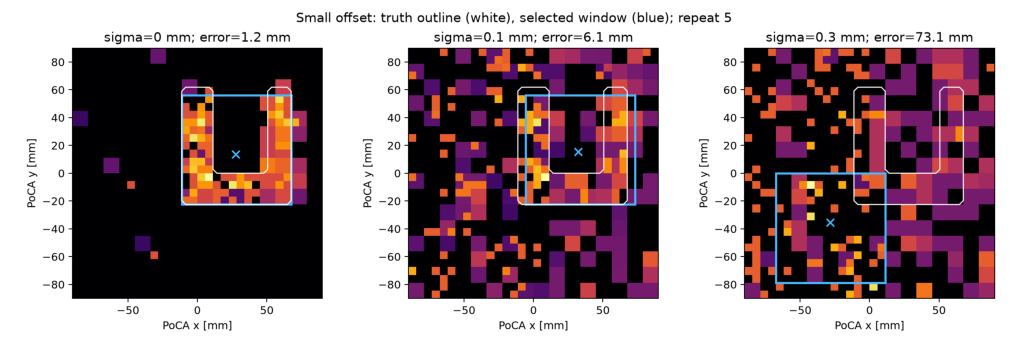

,position_sigma_mm,event_top5_weight_fraction_mean,background_top5_pixel_weight_fraction_mean,background_peak3x3_weight_fraction_mean,auto_window_background_fraction_mean
12,0.0,0.055,0.201,0.192,0.043
13,0.1,0.055,0.173,0.041,0.155
14,0.3,0.052,0.161,0.036,0.708


In [119]:
# 整体趋势图和同一批事件的三档误差图。
for image_name, height in (
    ('hotspot_failure_diagnostics.png', 8),
    ('small_offset_same_events_noise_progression.png', 5),
):
    plt.figure(figsize=(13, height))
    plt.imshow(plt.imread(HOTSPOT_DIR / image_name))
    plt.axis('off')
    plt.show()

# 验证“最高 5% 事件”与“最高 5% 背景正像素”不是同一个指标。
display(hotspot_summary[
    hotspot_summary['scenario'] == 'small_offset'
][[
    'position_sigma_mm', 'event_top5_weight_fraction_mean',
    'background_top5_pixel_weight_fraction_mean',
    'background_peak3x3_weight_fraction_mean',
    'auto_window_background_fraction_mean'
]].round(3))


## 44. 同一事件为什么会在噪声后进入筛选？

上一节看到目标外背景扩散，但还不知道它来自**原本通过筛选的事件 PoCA 偏移**，还是来自**新的事件进入筛选**。本节按“同一条缪子的行号”配对理想击中与加噪击中，比较两次是否通过 `theta >= 2 mrad` 和 PoCA 成像区域门槛。不同测量误差下仍使用同一批 5000 事件和同一组标准正态噪声。

- **始终通过（stable）**：理想击中与加噪击中均通过。
- **新进入（newly selected）**：理想击中未通过，加噪后通过；这不等于物理上“坏缪子”，只是筛选状态发生变化。
- **丢失（lost）**：理想击中通过，加噪后未通过。

“目标外权重”需要真值掩膜，仅用于事后判断误差来源；真实数据没有这种标签。


In [120]:
# 读取 5 个场景 × 4 档误差的事件配对统计。
SELECTION_DIR = Path('event_selection_shift_results')
selection_summary = pd.read_csv(
    SELECTION_DIR / 'event_selection_shift_summary.csv'
)

# 先看 0.10 和 0.30 mm：多少是新进入事件、它们贡献多少背景？
display(selection_summary[
    selection_summary['position_sigma_mm'].isin([0.10, 0.30])
][[
    'scenario', 'position_sigma_mm',
    'ideal_selected_events_mean', 'observed_selected_events_mean',
    'newly_selected_events_mean', 'newly_selected_fraction_mean',
    'newly_selected_background_weight_fraction_mean',
    'stable_poca_shift_median_mm_mean',
    'selected_target_weight_fraction_mean'
]].round(3))


,scenario,position_sigma_mm,ideal_selected_events_mean,observed_selected_events_mean,newly_selected_events_mean,newly_selected_fraction_mean,newly_selected_background_weight_fraction_mean,stable_poca_shift_median_mm_mean,selected_target_weight_fraction_mean
2,center,0.1,406.8,362.0,165.6,0.457,0.997,0.445,0.627
3,center,0.3,406.8,303.6,216.8,0.714,0.996,1.709,0.364
6,medium_offset,0.1,265.6,311.0,185.8,0.597,0.923,0.456,0.423
7,medium_offset,0.3,265.6,285.6,230.4,0.806,0.975,1.723,0.213
10,offcenter,0.1,407.8,355.2,167.6,0.472,0.892,0.451,0.548
11,offcenter,0.3,407.8,307.4,215.6,0.702,0.953,1.725,0.315
14,small,0.1,182.6,265.4,191.6,0.722,0.927,0.455,0.266
15,small,0.3,182.6,274.0,240.2,0.877,0.978,1.757,0.126
18,small_offset,0.1,192.4,281.4,188.6,0.671,0.955,0.466,0.356
19,small_offset,0.3,192.4,283.2,238.0,0.841,0.977,1.761,0.179


## 45. 当前最明确的失效机制

在独立的偏心小目标中，`sigma=0.30 mm` 时理想条件下平均约 **192** 条事件通过，噪声后约 **283** 条通过；噪声后通过的事件中约 **84%** 是“新进入”，它们贡献约 **98%** 的目标外散射权重。约 **97%** 的新进入事件在理想击中下散射角低于 2 mrad；约 **70%** 的理想 PoCA 本来就在成像范围外。这两个条件可以重叠，不能相加。

相比之下，始终通过的事件其 PoCA 位置中位移动约 **1.76 mm**（这是**单事件的配对位移**，不能与最终图像的几十毫米定位误差直接等同）。五个场景均出现明显的筛选成员替换，说明“门槛附近与原本区域外的事件因测量误差而进入成像”是当前背景扩散的重要来源；并不证明只靠修正稳定事件的 PoCA 位置就能解决问题。

研究决定：下一步优先构建**实际测量时可计算的事件可靠性指标**，例如围绕测得击中位置重复扰动后的通过概率与 PoCA 空间分散程度，并与现有简单多数门槛比较。这里用理想击中产生的“新进入”标签只能用于仿真诊断，**不能在测试图像重建时作为筛选条件**。


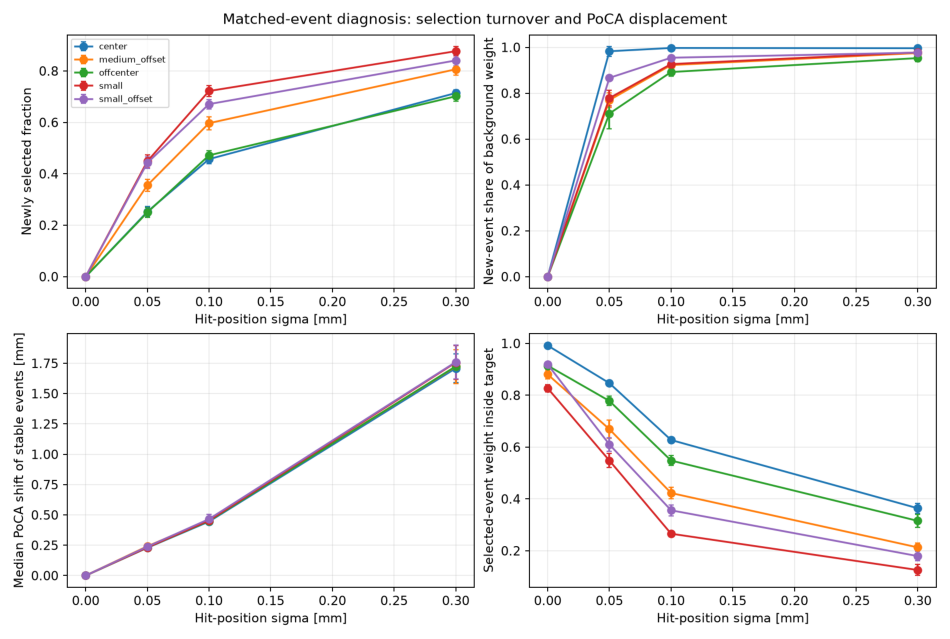

,position_sigma_mm,newly_selected_original_low_angle_fraction_mean,newly_selected_original_outside_roi_fraction_mean,stable_poca_shift_p90_mm_mean
17,0.05,0.931,0.601,0.431
18,0.10,0.958,0.681,0.801
19,0.30,0.973,0.701,2.739


In [121]:
# 四幅图依次为：新进入占比、背景权重来源、稳定事件 PoCA 位移、目标内权重。
plt.figure(figsize=(12, 9))
plt.imshow(plt.imread(SELECTION_DIR / 'event_selection_shift_diagnostics.png'))
plt.axis('off')
plt.show()

# 单独检查新进入事件在理想条件下的散射角和 PoCA 区域状态。
display(selection_summary[
    (selection_summary['scenario'] == 'small_offset')
    & (selection_summary['position_sigma_mm'] > 0)
][[
    'position_sigma_mm', 'newly_selected_original_low_angle_fraction_mean',
    'newly_selected_original_outside_roi_fraction_mean',
    'stable_poca_shift_p90_mm_mean'
]].round(3))


## 46. 连续事件可靠性：从诊断到可用的权重

前两节使用理想 Geant4 击中判断哪些事件“噪声后才进入筛选”；这个标签只适合**诊断**，真实探测器不会告诉我们理想击中。本节改用实际可以计算的量：对每条**测得的四层击中**重复加测量误差，做 12 次重建，记录它有几次仍通过同一套 hard 散射角修正和 PoCA 成像区域筛选。

记通过频率为 `p`，通过的 PoCA 点 XY 坐标 RMS 分散为 `s`，细体素宽度为 `h=5.625 mm`。对同一组 nominal hard 通过事件比较：

- `hard`：直接使用已有的截断角度权重；
- `majority`：`p >= 0.5` 时保留原权重，否则删除；
- `pass_prob`：原权重乘 `p`；
- `pass_spread`：原权重乘 `p / (1 + (s/h)²)`。

这次的 `majority` 与更早的“候选散射点多数门槛”**不是完全相同的实现**：为了公平比较，四种方法都从同一批 nominal hard 事件出发，并且扰动后都采用相同的角度噪声底修正。真值掩膜只在最后评价 IoU 与定位误差时使用。


In [122]:
# 读取已运行完毕的结果；这里不重新抽样或执行 Geant4。
QUALITY_DIR = Path('continuous_event_quality_results')
quality_summary = pd.read_csv(
    QUALITY_DIR / 'continuous_event_quality_summary.csv'
)

# 固定 5000 条输入事件，查看 0.10 / 0.30 mm 两个代表性条件。
display(quality_summary[
    (quality_summary['event_count'] == 5000)
    & quality_summary['position_sigma_mm'].isin([0.10, 0.30])
][[
    'scenario', 'method', 'position_sigma_mm',
    'iou_mean', 'global_error_mm_mean', 'auto_error_mm_mean',
    'contributing_events_mean', 'weight_fraction_of_hard_mean'
]].round(3))


,scenario,method,position_sigma_mm,iou_mean,global_error_mm_mean,auto_error_mm_mean,contributing_events_mean,weight_fraction_of_hard_mean
10,center,hard,0.1,0.400,5.963,5.551,362.0,1.000
11,center,hard,0.3,0.219,9.796,48.616,303.6,1.000
22,center,majority,0.1,0.438,3.737,8.662,204.6,0.591
23,center,majority,0.3,0.245,10.662,48.090,111.4,0.372
34,center,pass_prob,0.1,0.392,4.400,7.990,361.2,0.519
35,center,pass_prob,0.3,0.229,9.707,47.831,301.6,0.406
46,center,pass_spread,0.1,0.388,4.389,8.020,361.2,0.516
47,center,pass_spread,0.3,0.222,9.709,47.976,301.6,0.386
58,medium_offset,hard,0.1,0.322,14.237,5.914,311.0,1.000
59,medium_offset,hard,0.3,0.116,21.272,46.103,285.6,1.000


## 47. 为什么还不能说它优于基线？

偏心小目标、5000 事件、`sigma=0.30 mm` 是一个明显获益例子：自动窗口误差 `hard` 约 **45.20 mm**，`pass_prob` 约 **22.23 mm**，`pass_spread` 约 **21.76 mm**；IoU 则分别约 **0.081、0.123、0.127**。但是偏心大目标的同一噪声条件下，自动窗口误差由 `hard` 的约 **16.09 mm** 反而升到 `pass_prob` 的 **28.80 mm**。低噪声与低事件数也有类似胜负混合。

因此，本轮只能得出：**连续通过概率有潜力，但尚未跨场景稳定获益**。附加空间分散因子的收益很小：0.30 mm 时 nominal 事件的 PoCA 扰动分散中位数约 **1.2 mm**，低于细体素宽度 5.625 mm，所以 `(1+(s/h)²)` 大多接近 1。若为了强行改善而改用特别小的尺度，会变成针对已见场景调参，不能作为可靠结论。

这五个场景此前都已参与问题诊断，**不是新的独立测试集**。此外每种条件只有 5 次来自同一份 Geant4 CSV 的子样本重复，尚不能证明方法对新的目标几何、入射能谱和探测器误差稳健。下一步更应检查 `p` 能否区分真正造成背景的事件，并考虑事件与局部体素的一致性，而不是仅再加一个全局经验阈值。


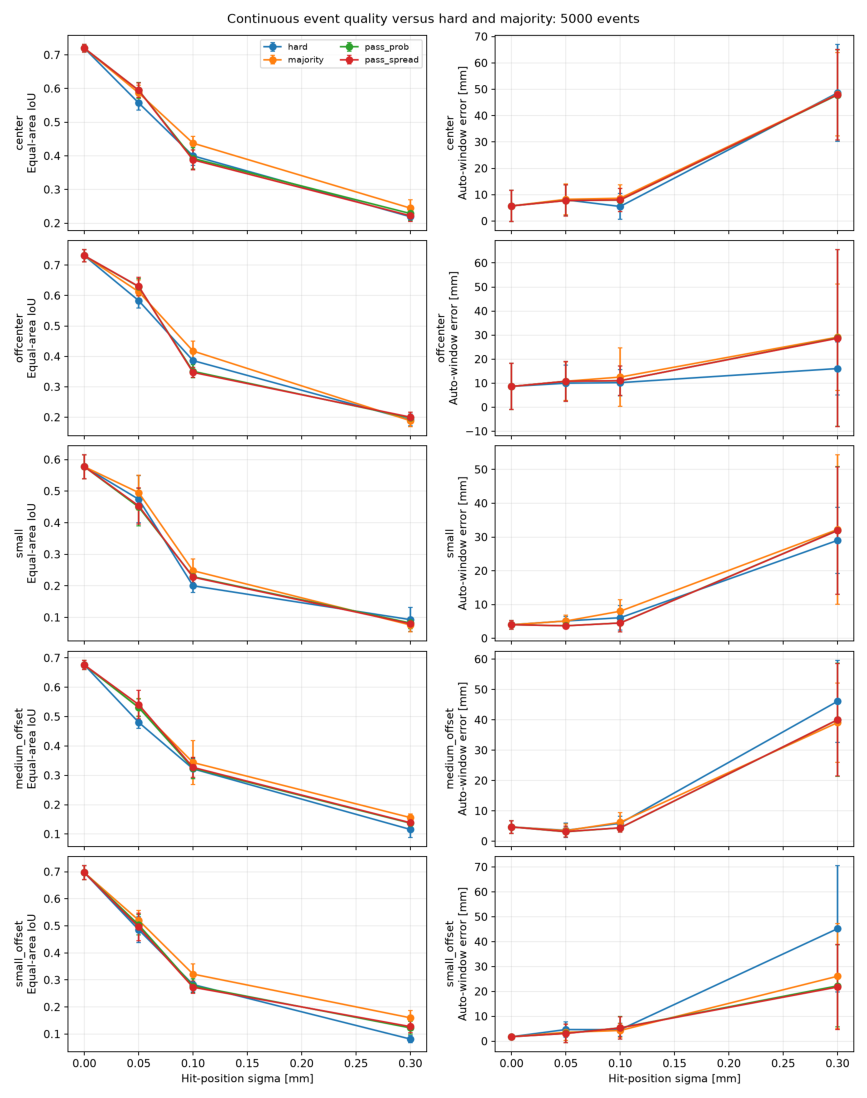

,iou_win,auto_win
method,,
majority,33,21
pass_prob,23,26
pass_spread,26,24


In [123]:
# 五个场景的 5000 事件对照。左边 IoU 越高越好，右边自动定位误差越低越好。
plt.figure(figsize=(11, 14))
plt.imshow(plt.imread(QUALITY_DIR / 'continuous_event_quality_5000.png'))
plt.axis('off')
plt.show()

# 汇总不同事件数/误差组合中，相比 hard 基线各方法赢了多少组。
hard_rows = quality_summary[quality_summary['method'] == 'hard'][[
    'scenario', 'event_count', 'position_sigma_mm',
    'iou_mean', 'auto_error_mm_mean'
]].rename(columns={
    'iou_mean': 'hard_iou',
    'auto_error_mm_mean': 'hard_auto_error_mm',
})
paired_quality = quality_summary.merge(
    hard_rows, on=['scenario', 'event_count', 'position_sigma_mm']
)
paired_quality = paired_quality[
    (paired_quality['method'] != 'hard')
    & (paired_quality['position_sigma_mm'] > 0)
].copy()
paired_quality['iou_win'] = paired_quality['iou_mean'] > paired_quality['hard_iou']
paired_quality['auto_win'] = (
    paired_quality['auto_error_mm_mean'] < paired_quality['hard_auto_error_mm']
)
display(paired_quality.groupby('method')[['iou_win', 'auto_win']].sum())


## 48. 事件质量策略的逐重复配对复核

这份 Notebook 用于**阅读和解释**已运行的实验结果；生成完整 CSV 和图的脚本是 `run_paired_event_quality_validation.py`。

所有方法在同一个场景、事件数、重复和位置误差组合下配对比较。增益为正表示比 `hard` 更好。请注意：重复抽样不等于独立探测器实验。

In [1]:
from pathlib import Path
import pandas as pd

# VS Code 有时以项目根目录作为工作目录，有时以 Notebook 所在目录作为工作目录。
base = Path.cwd()
results = base / 'paired_event_quality_results'
if not results.exists():
    results = base / 'muon_analysis' / 'paired_event_quality_results'
if not results.exists():
    raise FileNotFoundError('请先运行 run_paired_event_quality_validation.py')
overall = pd.read_csv(results / 'paired_overall_noisy.csv')
conditions = pd.read_csv(results / 'paired_by_condition.csv')
overall[['method', 'paired_n', 'iou_gain_mean', 'iou_win_fraction',
         'global_error_gain_mm_mean', 'auto_error_gain_mm_mean']].round(4)

,method,paired_n,iou_gain_mean,iou_win_fraction,global_error_gain_mm_mean,auto_error_gain_mm_mean
0,majority,225,0.0234,0.7022,0.4009,-0.0223
1,pass_prob,225,0.0014,0.4978,1.1170,1.7611
2,pass_spread,225,0.0025,0.4800,1.1104,1.0094


### 检查各场景，而不是只看总体平均

下面固定 5000 个输入事件。表中是每个场景与探测器误差下，相对 `hard` 的平均 IoU 增益。负数代表该方法反而降低 IoU。

In [2]:
view = conditions[(conditions['event_count'] == 5000) &
                  (conditions['position_sigma_mm'] > 0)]
view.pivot_table(index=['scenario', 'position_sigma_mm'],
                 columns='method', values='iou_gain_mean').round(3)

method                           majority  pass_prob  pass_spread
scenario      position_sigma_mm                                  
center        0.05                  0.030      0.038        0.038
              0.10                  0.038     -0.008       -0.012
              0.30                  0.026      0.009        0.003
medium_offset 0.05                  0.051      0.051        0.061
              0.10                  0.021      0.002        0.005
              0.30                  0.040      0.021        0.023
offcenter     0.05                  0.029      0.046        0.047
              0.10                  0.031     -0.035       -0.039
              0.30                 -0.003      0.007        0.009
small         0.05                  0.021     -0.025       -0.021
              0.10                  0.048      0.029        0.027
              0.30                 -0.017     -0.011       -0.013
small_offset  0.05                  0.035      0.018        0.010
              0.10                  0.039     -0.005       -0.010
              0.30                  0.079      0.041        0.046

### 读图提示

左图是 IoU 相对 `hard` 的变化，右图是自动窗口定位误差的减少量；两图的零线表示与 `hard` 持平。不能仅凭总体曲线宣布某个方法在全部场景最优。

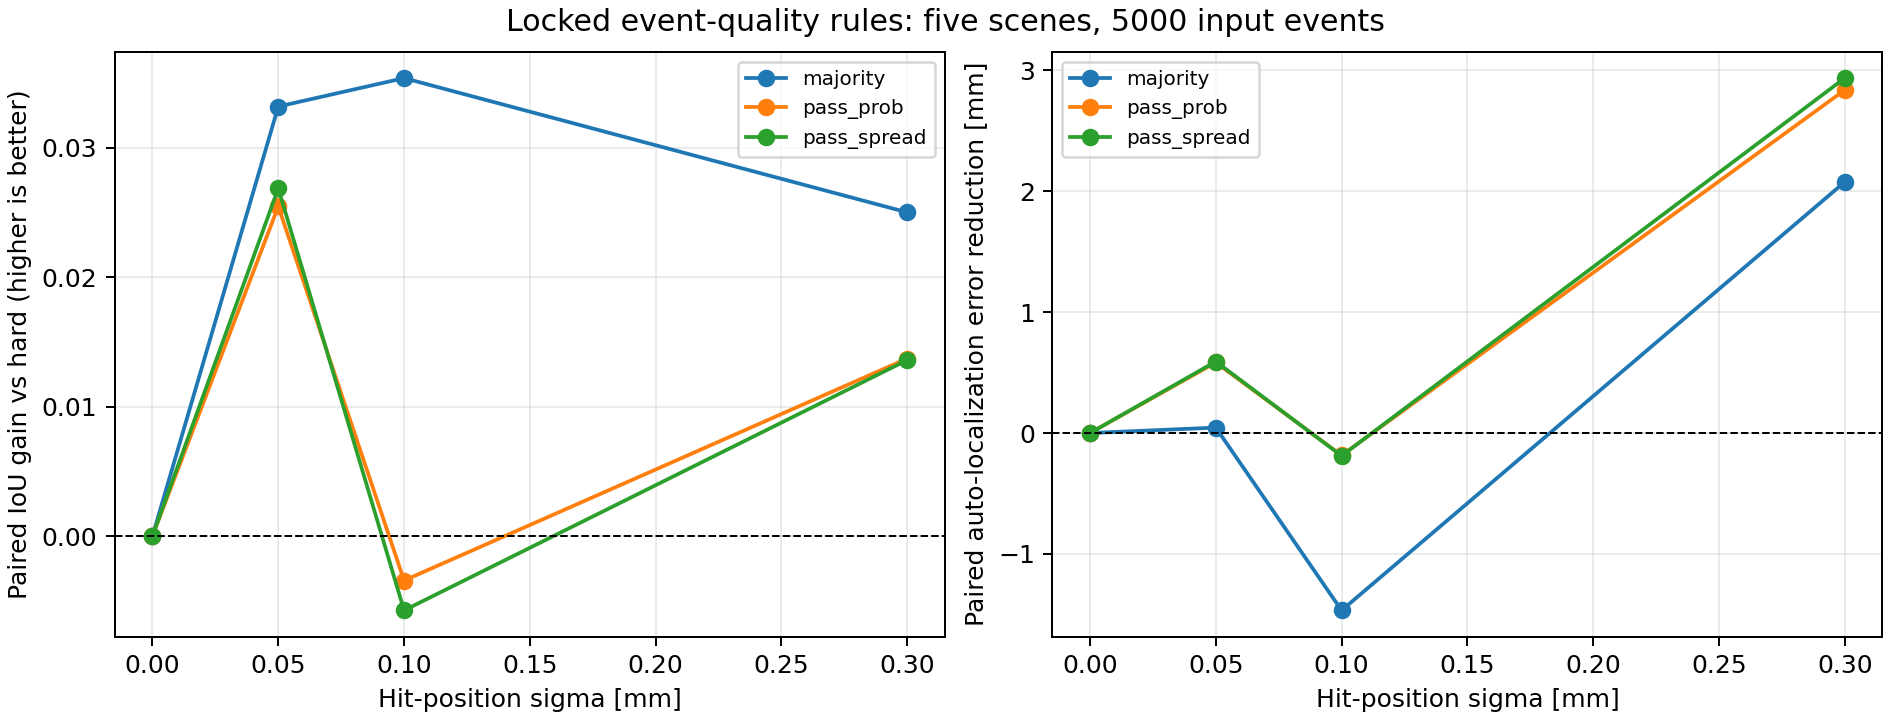

In [3]:
from IPython.display import display, Image
display(Image(filename=str(results / 'paired_tradeoff_5000.png')))

## 49. IoU 改善但局部定位变差的失败分析

这份 Notebook 用已有 CSV 和图片解释**事后挑选的失败样例**，不能用它们证明新算法泛化。生成数据的两个脚本是 `diagnose_event_quality_localization.py` 和 `run_event_quality_localizer_ablation.py`。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

base = Path.cwd()
if not (base / 'event_quality_failure_diagnosis').exists():
    base = base / 'muon_analysis'
cases_dir = base / 'event_quality_failure_diagnosis'
ablation_dir = base / 'event_quality_localizer_ablation_results'
if not cases_dir.exists() or not ablation_dir.exists():
    raise FileNotFoundError('请先运行两份诊断与消融脚本')
cases = pd.read_csv(cases_dir / 'diagnostic_cases.csv')
cases[['scenario', 'event_count', 'repeat', 'position_sigma_mm',
       'method', 'iou', 'global_error_mm', 'auto_error_mm',
       'window_bins', 'window_start_x', 'window_start_y']].round(3)

,scenario,event_count,repeat,position_sigma_mm,method,iou,global_error_mm,auto_error_mm,window_bins,window_start_x,window_start_y
0,offcenter,5000,1,0.1,hard,0.384,15.351,17.544,18,13,2
1,offcenter,5000,1,0.1,majority,0.456,7.331,34.097,14,17,2
2,offcenter,5000,2,0.3,hard,0.207,31.832,33.870,14,9,1
3,offcenter,5000,2,0.3,majority,0.213,35.606,64.425,14,3,1
4,small,3000,4,0.3,hard,0.054,5.709,5.877,18,6,6
5,small,3000,4,0.3,majority,0.064,18.323,64.452,18,0,14


### 看偏心目标的一次窗口跳变

青色是真值轮廓与中心，仅用于事后诊断；绿色为算法自己选的窗口与定位点。比较左右两图：右图的 IoU 较高，但绿色窗口缩小并偏向 U 型一侧。

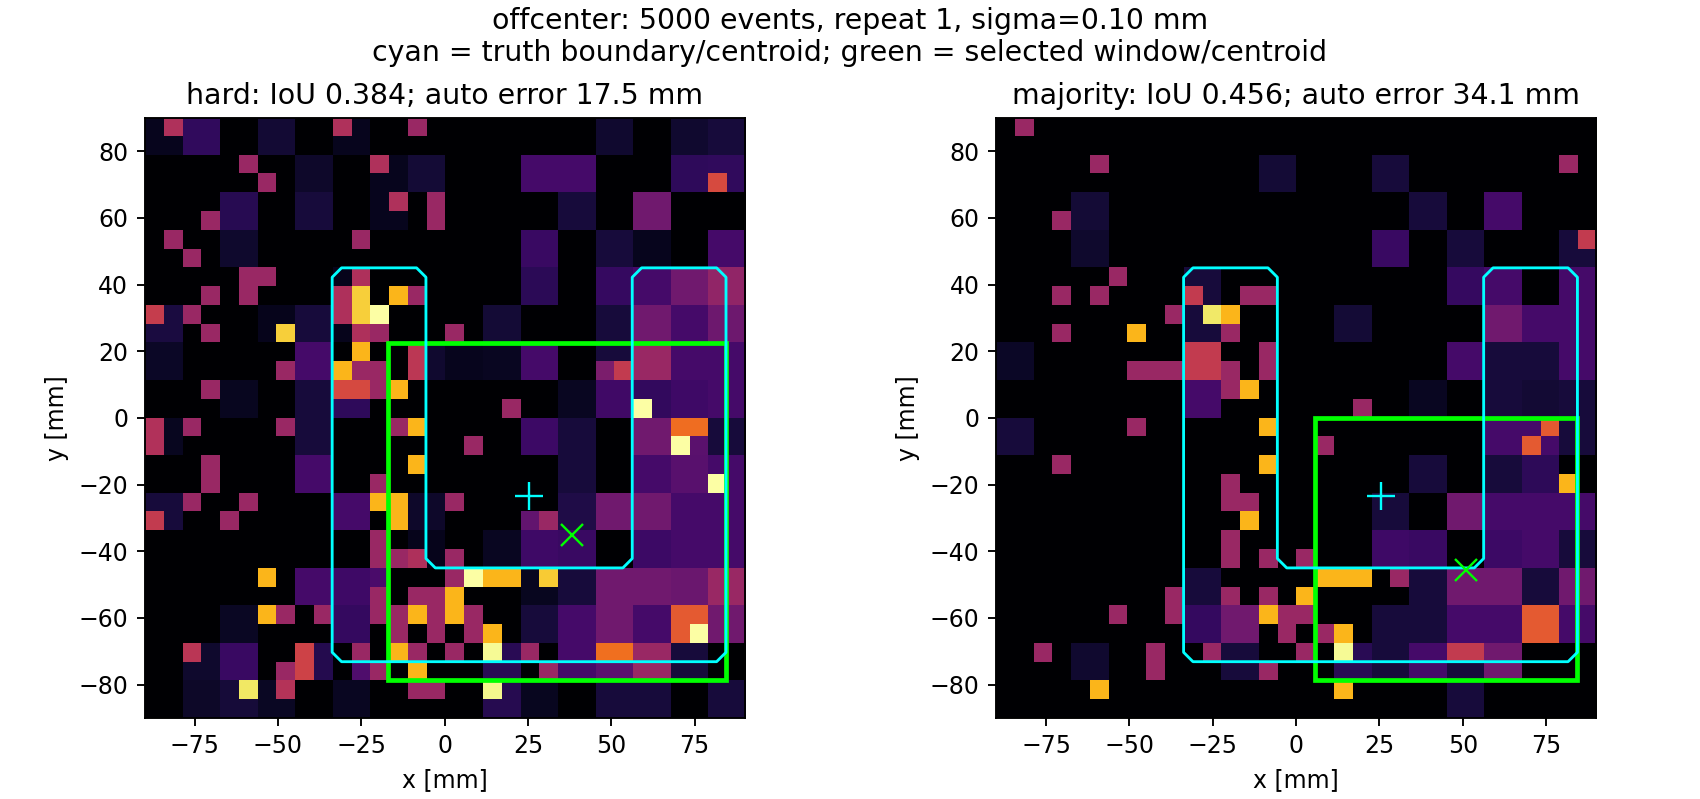

In [2]:
display(Image(filename=str(cases_dir / 'offcenter_5000_r1_sigma0.10.png')))

### 用全部条件检查定位器

下面只看非零位置误差。均值衡量总体水平，P90 衡量坏情况的长尾。固定24格是已有强对照，但使用了目标最大尺度的先验。

In [3]:
all_runs = pd.read_csv(ablation_dir / 'localizer_ablation_by_repeat.csv')
noisy = all_runs[all_runs['position_sigma_mm'] > 0]
columns = ['global_error_mm', 'fixed24_error_mm',
           'multiscale_error_mm', 'robust_multiscale_error_mm']
noisy.groupby('method')[columns].agg(['mean', lambda x: x.quantile(.9)]).round(2)

global_error_mm            fixed24_error_mm             \
                    mean <lambda_0>             mean <lambda_0>   
method                                                            
hard               13.34      28.37            14.40      31.82   
majority           12.94      28.87            13.86      33.20   

         multiscale_error_mm            robust_multiscale_error_mm             
                        mean <lambda_0>                       mean <lambda_0>  
method                                                                         
hard                   20.81      56.04                      20.87      53.89  
majority               20.84      56.94                      21.82      57.49

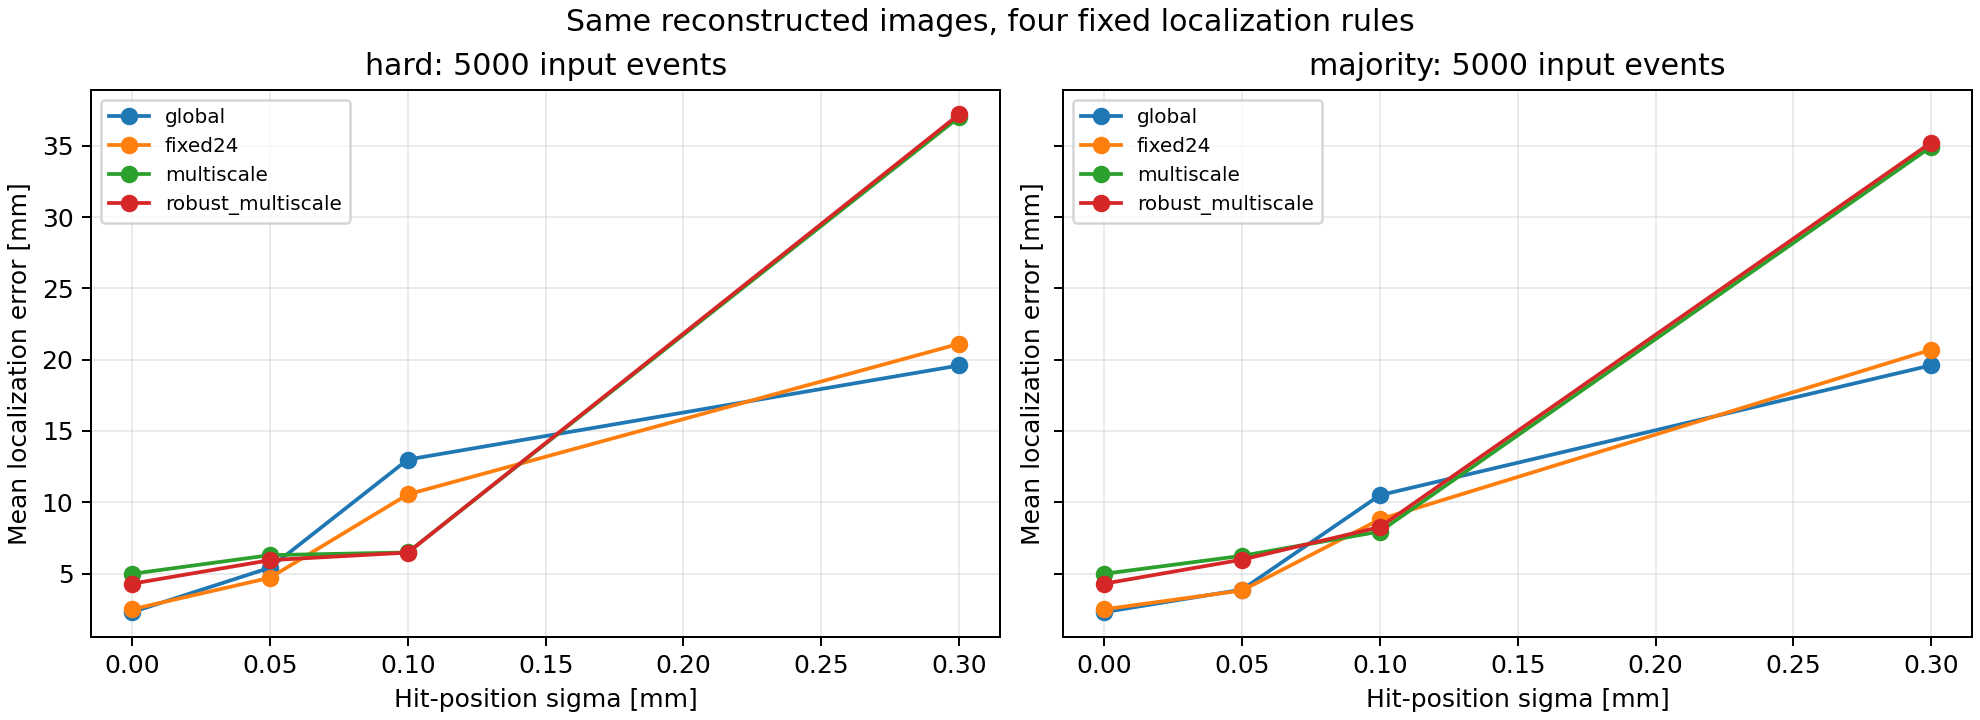

In [4]:
display(Image(filename=str(ablation_dir / 'localizer_ablation_5000.png')))

## 留出 L 型目标：固定规则的跨形状验证

这一节只读取 `heldout_l_shape_results/` 中的 CSV 与图。L 型铝目标没有参与前面 U 型场景的阈值、40% 细分和事件质量规则选择。Geant4 数据由 `B1/run_l_shape_validation.mac` 单独生成，完整四层击中有 9,976 条。

比较方法共享相同的事件子集和噪声。表中正的 IoU 差表示轮廓改善；正的误差减少表示定位改善。这里的 45 个非零误差配对单元是仿真子样本，不是 45 次独立物理实验。真值 L 掩膜只在最后评分时使用。

重点观察：理想击中下 40% 细分的 IoU 较高，但加入击中误差后，完全粗 16³ 往往更稳；多数通过筛选改善平均 IoU 和全图质心，却可能恶化多尺度自动窗口定位。请结合下方三个指标看图，不要只看 IoU。


,method,paired_n,iou_gain_mean,iou_win_fraction,global_error_reduction_mm_mean,auto_error_reduction_mm_mean
0,hard_coarse16,45,0.0387,0.8000,-0.0178,0.4822
1,hard_fixed32,45,0.0018,0.5111,-0.0378,0.0244
2,majority_adaptive40,45,0.0305,0.8222,1.9631,-1.0917
3,pass_prob_adaptive40,45,0.0050,0.4444,1.7103,0.1828
4,pass_spread_adaptive40,45,0.0086,0.5333,1.6865,0.4638


,method,position_sigma_mm,iou_mean,global_error_mm_mean,auto_error_mm_mean
8,hard_adaptive40,0.00,0.7058,2.5408,11.6564
9,hard_adaptive40,0.05,0.5095,8.8042,10.3984
10,hard_adaptive40,0.10,0.3715,15.9854,10.4705
11,hard_adaptive40,0.30,0.1818,23.2136,18.7574
20,hard_coarse16,0.00,0.6755,2.5598,10.3944
21,hard_coarse16,0.05,0.5975,8.8055,9.7285
22,hard_coarse16,0.10,0.4103,15.8824,10.6221
23,hard_coarse16,0.30,0.1914,23.2642,13.4716
32,hard_fixed32,0.00,0.5891,2.4699,12.5477
33,hard_fixed32,0.05,0.4533,8.8566,13.0117


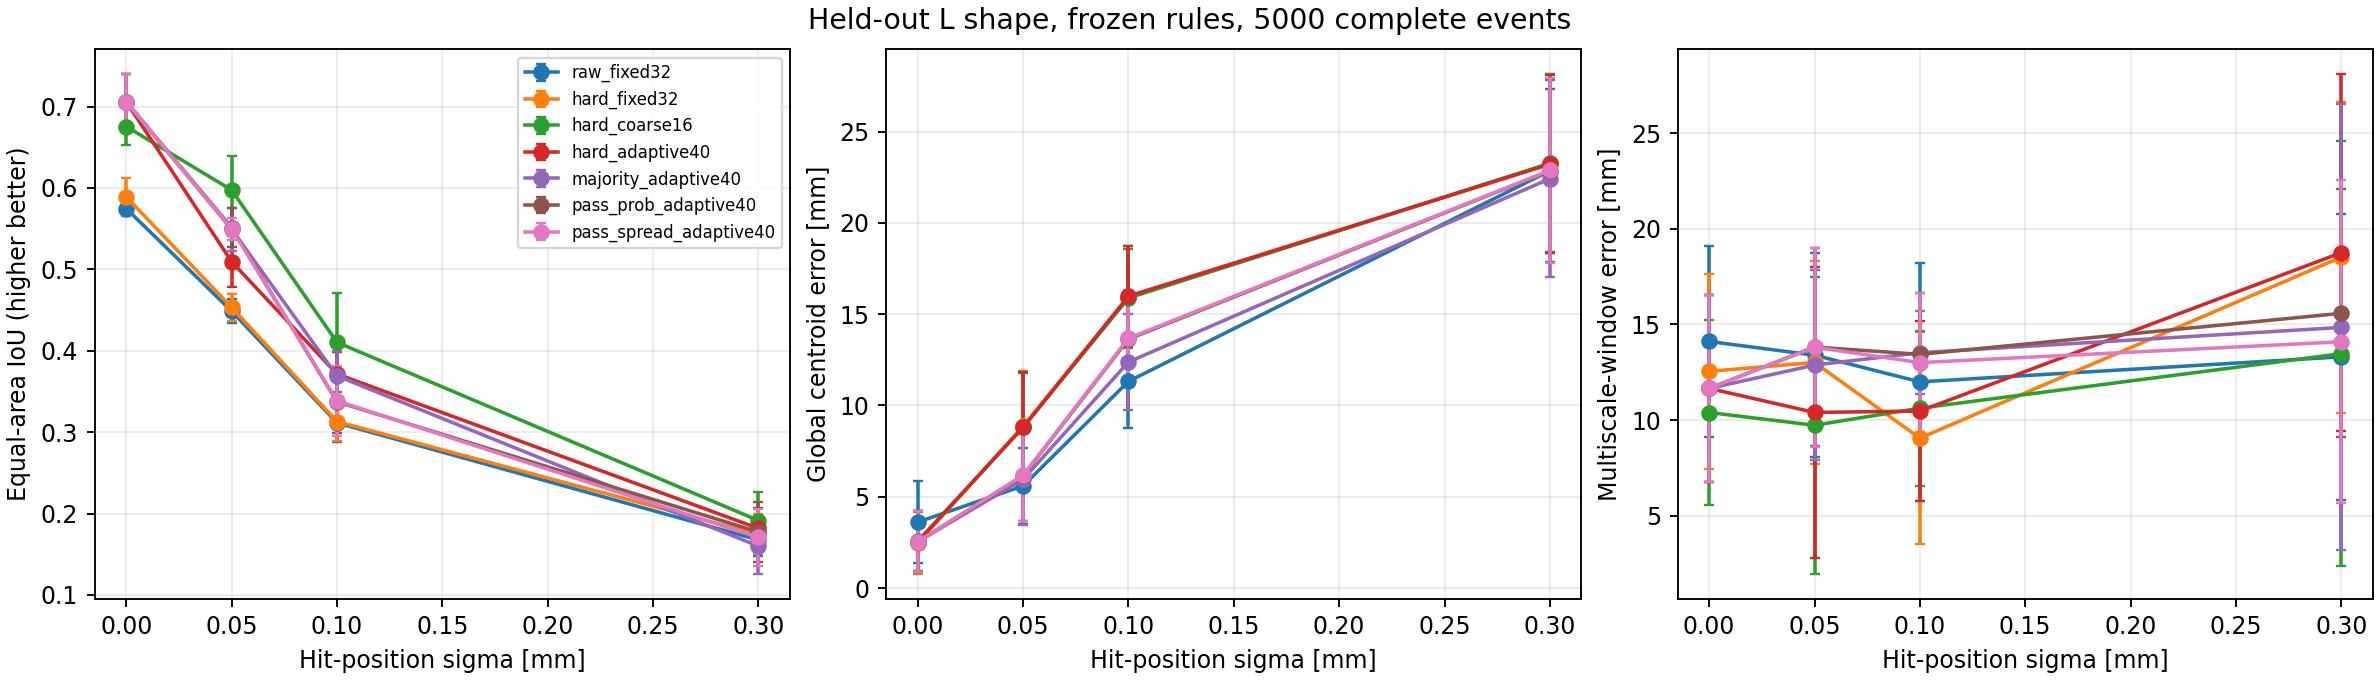

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# 当前 Notebook 位于 muon_analysis；所有实验数据仍留在该目录。
heldout_dir = Path("heldout_l_shape_results")
paired_l = pd.read_csv(heldout_dir / "heldout_l_shape_paired_summary.csv")
summary_l = pd.read_csv(heldout_dir / "heldout_l_shape_summary.csv")

# 正的 IoU 增益或误差减少才是改善；负值不要误读成收益。
display(paired_l.round(4))

# 5000 条输入事件下：固定分辨率、40% 细分及质量规则并排比较。
columns_l = ["method", "position_sigma_mm", "iou_mean",
             "global_error_mm_mean", "auto_error_mm_mean"]
display(summary_l.loc[summary_l.event_count.eq(5000), columns_l].round(4))

display(Image(filename=str(heldout_dir / "heldout_l_shape_5000.png")))


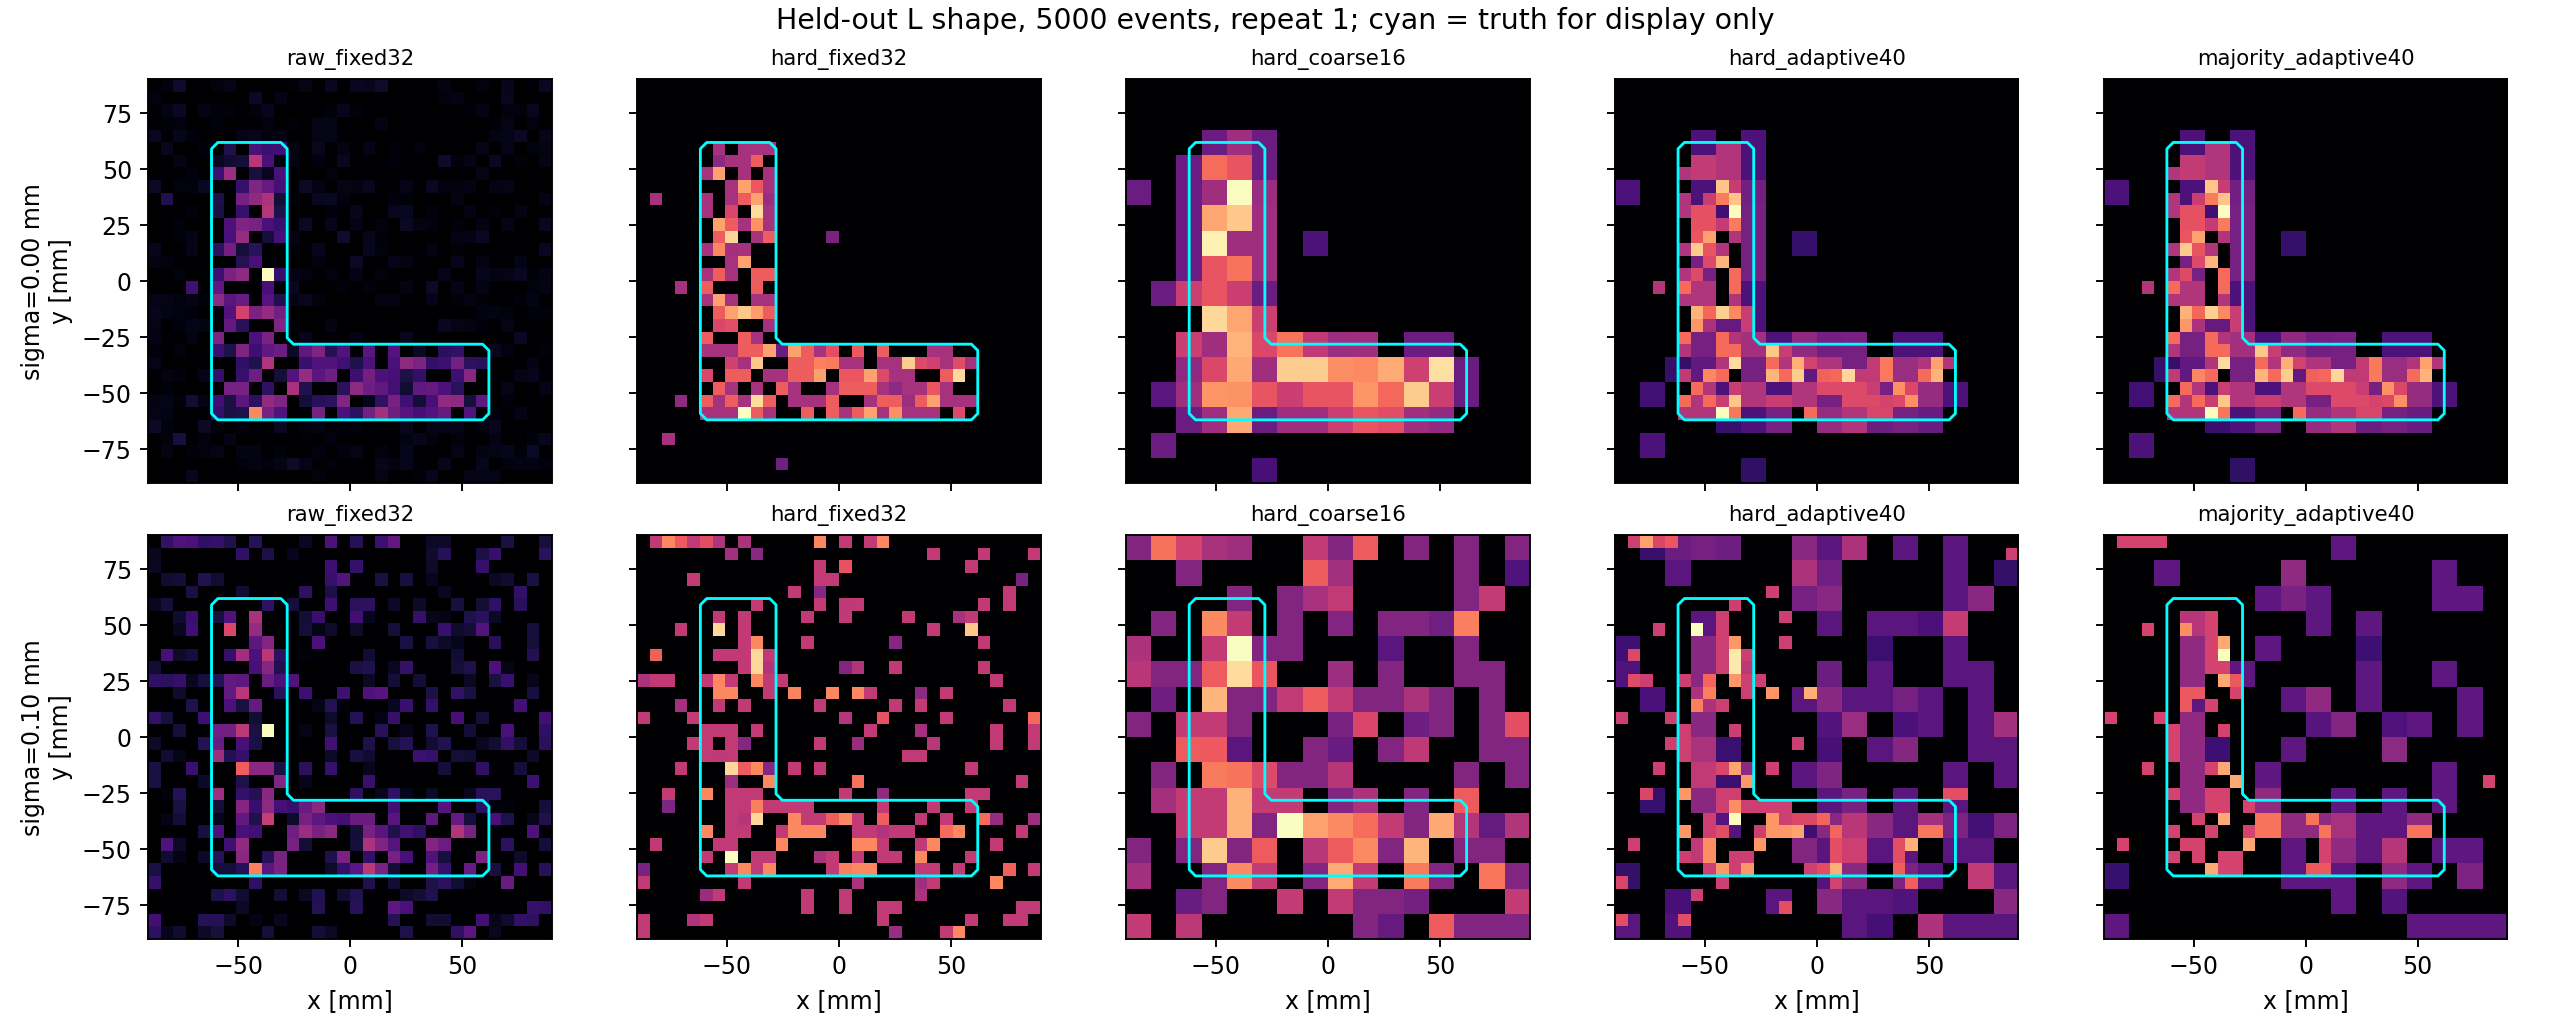

In [2]:
# 第一行是理想击中，第二行加入 0.10 mm 位置误差；青线仅用于事后对照。
# 各面板独立归一化，所以不要用亮度比较绝对散射强度。
display(Image(filename=str(heldout_dir / "heldout_l_shape_reconstruction.png")))


## 局部有效统计量细分：开发实验与负结果

这一节只读取 `noise_aware_refinement_results/`，不重新运行 Geant4。规则用粗体素有效事件数 `n_eff=(Σw)²/Σw²` 和已知击中误差来判断细分，不使用 U 型真值做决策。每种方法共享事件和噪声，真值只用于评分。

最初要求每个粗体素有约 8 个有效事件，但现有数据太稀疏，全部退化成粗网格；这份试验保存在 `noise_aware_refinement_gate8_results/`。改为最低 2 个有效事件后，含噪时仍几乎不细分。看到的 IoU 增益主要来自粗网格平滑，而非新规则成功，因此当前**不能写成已验证的创新方法**。L 型结果已经启发了本规则，不能再次充当它的独立留出测试。详细限制见结果目录中的 `research_note.md`。


,method,position_sigma_mm,iou_mean,auto_error_mm_mean,refined_coarse_voxels_mean
8,adaptive40,0.00,0.717120,7.728166,134.2
9,adaptive40,0.05,0.568655,5.263151,139.0
10,adaptive40,0.10,0.413754,12.289618,138.4
11,adaptive40,0.30,0.227676,44.676454,115.2
20,coarse16,0.00,0.670228,9.158089,0.0
21,coarse16,0.05,0.624300,6.296382,0.0
22,coarse16,0.10,0.469820,11.970971,0.0
23,coarse16,0.30,0.253292,43.384484,0.0
32,fixed32,0.00,0.627625,5.664755,4096.0
33,fixed32,0.05,0.495980,5.370229,4096.0


,method,paired_n,iou_gain_mean,iou_win_fraction,global_error_reduction_mm_mean,auto_error_reduction_mm_mean
0,coarse16,45,0.033136,0.800000,0.034254,-1.392823
1,fixed32,45,-0.055482,0.111111,0.009956,0.032921
2,noise_aware,45,0.033032,0.800000,0.032509,-1.390828


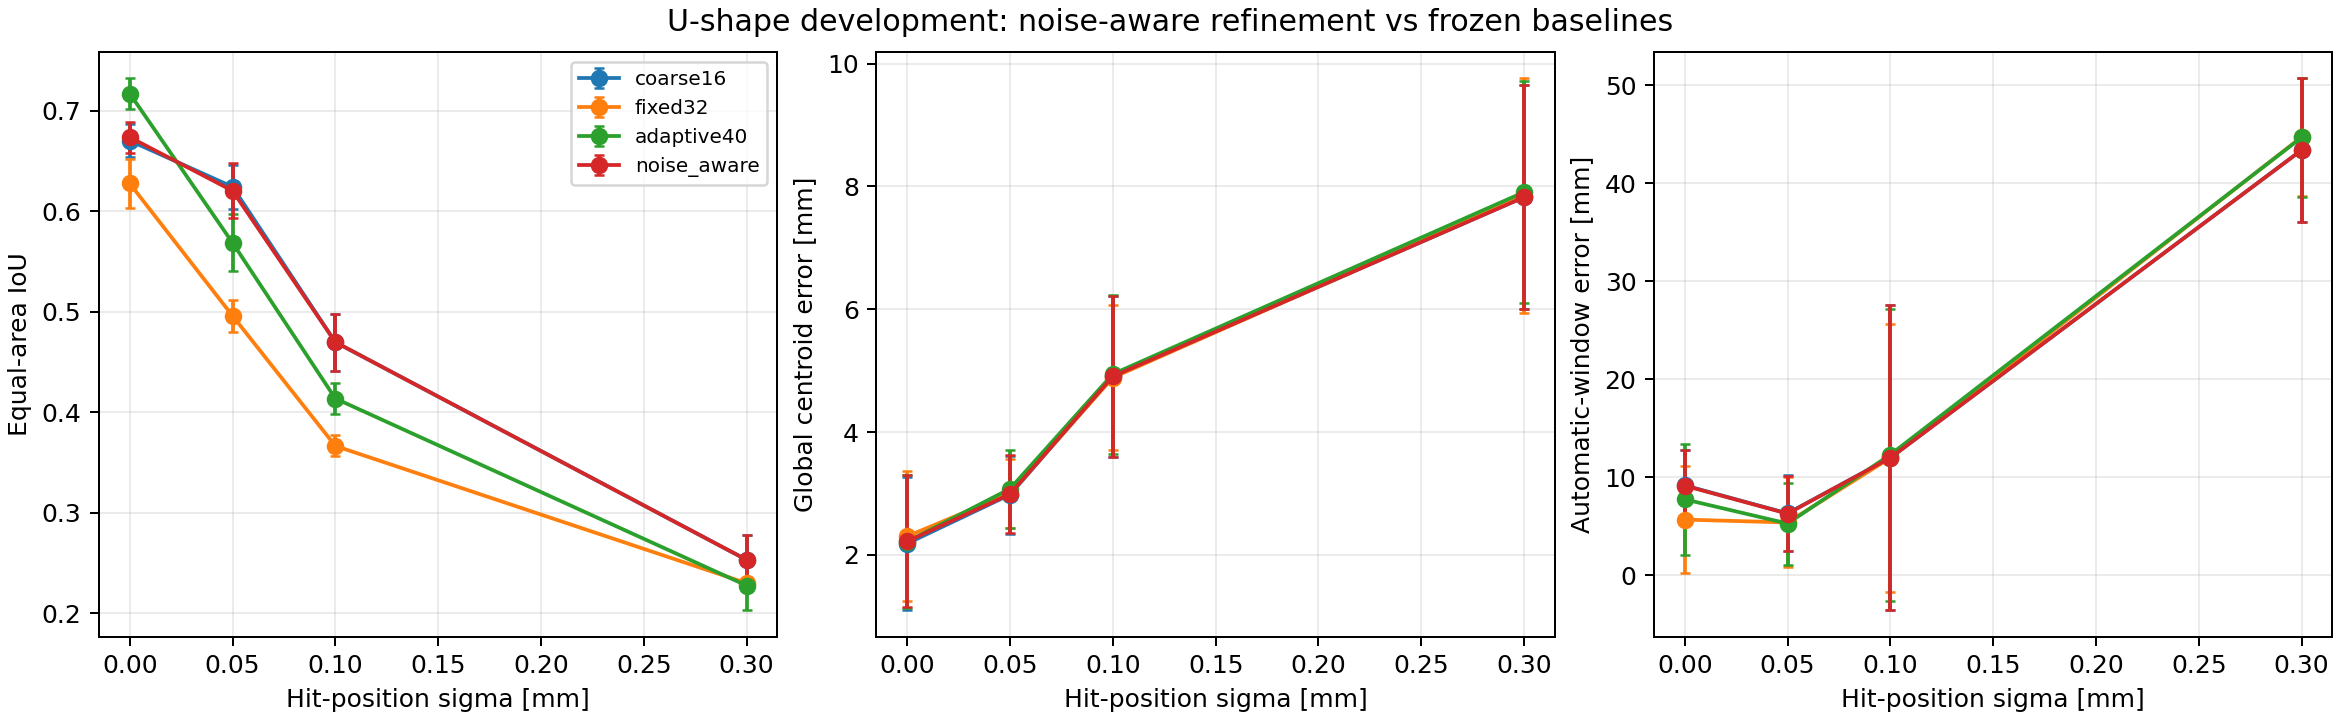

In [3]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

noise_dir = Path('noise_aware_refinement_results')  # Notebook 工作目录为 muon_analysis
noise_summary = pd.read_csv(noise_dir / 'summary.csv')
noise_pairs = pd.read_csv(noise_dir / 'paired_noisy_summary.csv')
display(noise_summary.loc[noise_summary.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_mean', 'auto_error_mm_mean', 'refined_coarse_voxels_mean']])
display(noise_pairs)
display(Image(filename=str(noise_dir / 'comparison.png')))


## 沿 z 共享统计量：为什么事件更多仍可能成像更差

这轮把 1、4、16 个相邻粗 z 层的事件统计量合并来决定 XY 细分，但重建时保留各 z 层的权重。结果只用于 U 型开发集分析，不能称为独立形状验证。读取下面的汇总表时，重点同时看 IoU、自动窗口误差和真正被细分的粗 z 切片数。

在 5000 条输入、σ=0.05 mm 条件下，汇总 16 层会大幅增加细分区域，但 IoU 从粗网格的约 0.624 降至约 0.537。它的名义 z 输出网格也只有 16 层（每层 12.5 mm），不能把二维投影表现描述成三维定位改进。完整口径和限制见 `z_pooled_refinement_results/research_note.md`。


,method,position_sigma_mm,iou_mean,auto_error_mm_mean,refined_coarse_slices_mean,max_effective_events_mean
8,adaptive40,0.00,0.717120,7.728166,134.2,NaN
9,adaptive40,0.05,0.568655,5.263151,139.0,NaN
10,adaptive40,0.10,0.413754,12.289618,138.4,NaN
11,adaptive40,0.30,0.227676,44.676454,115.2,NaN
20,coarse16,0.00,0.670228,9.158089,0.0,NaN
21,coarse16,0.05,0.624300,6.296382,0.0,NaN
22,coarse16,0.10,0.469820,11.970971,0.0,NaN
23,coarse16,0.30,0.253292,43.384484,0.0,NaN
32,noise_aware_3d,0.00,0.673668,9.123052,48.0,NaN
33,noise_aware_3d,0.05,0.620371,6.272081,2.8,NaN


,method,paired_n,iou_gain_mean,iou_win_fraction,global_error_reduction_mm_mean,auto_error_reduction_mm_mean
0,coarse16,45,0.033136,0.800000,0.034254,-1.392823
1,noise_aware_3d,45,0.033032,0.800000,0.032509,-1.390828
2,z_pool_1,45,0.033032,0.800000,0.032509,-1.390828
3,z_pool_16,45,0.011074,0.644444,0.009693,-1.401397
4,z_pool_4,45,0.029371,0.777778,0.031706,-1.436348


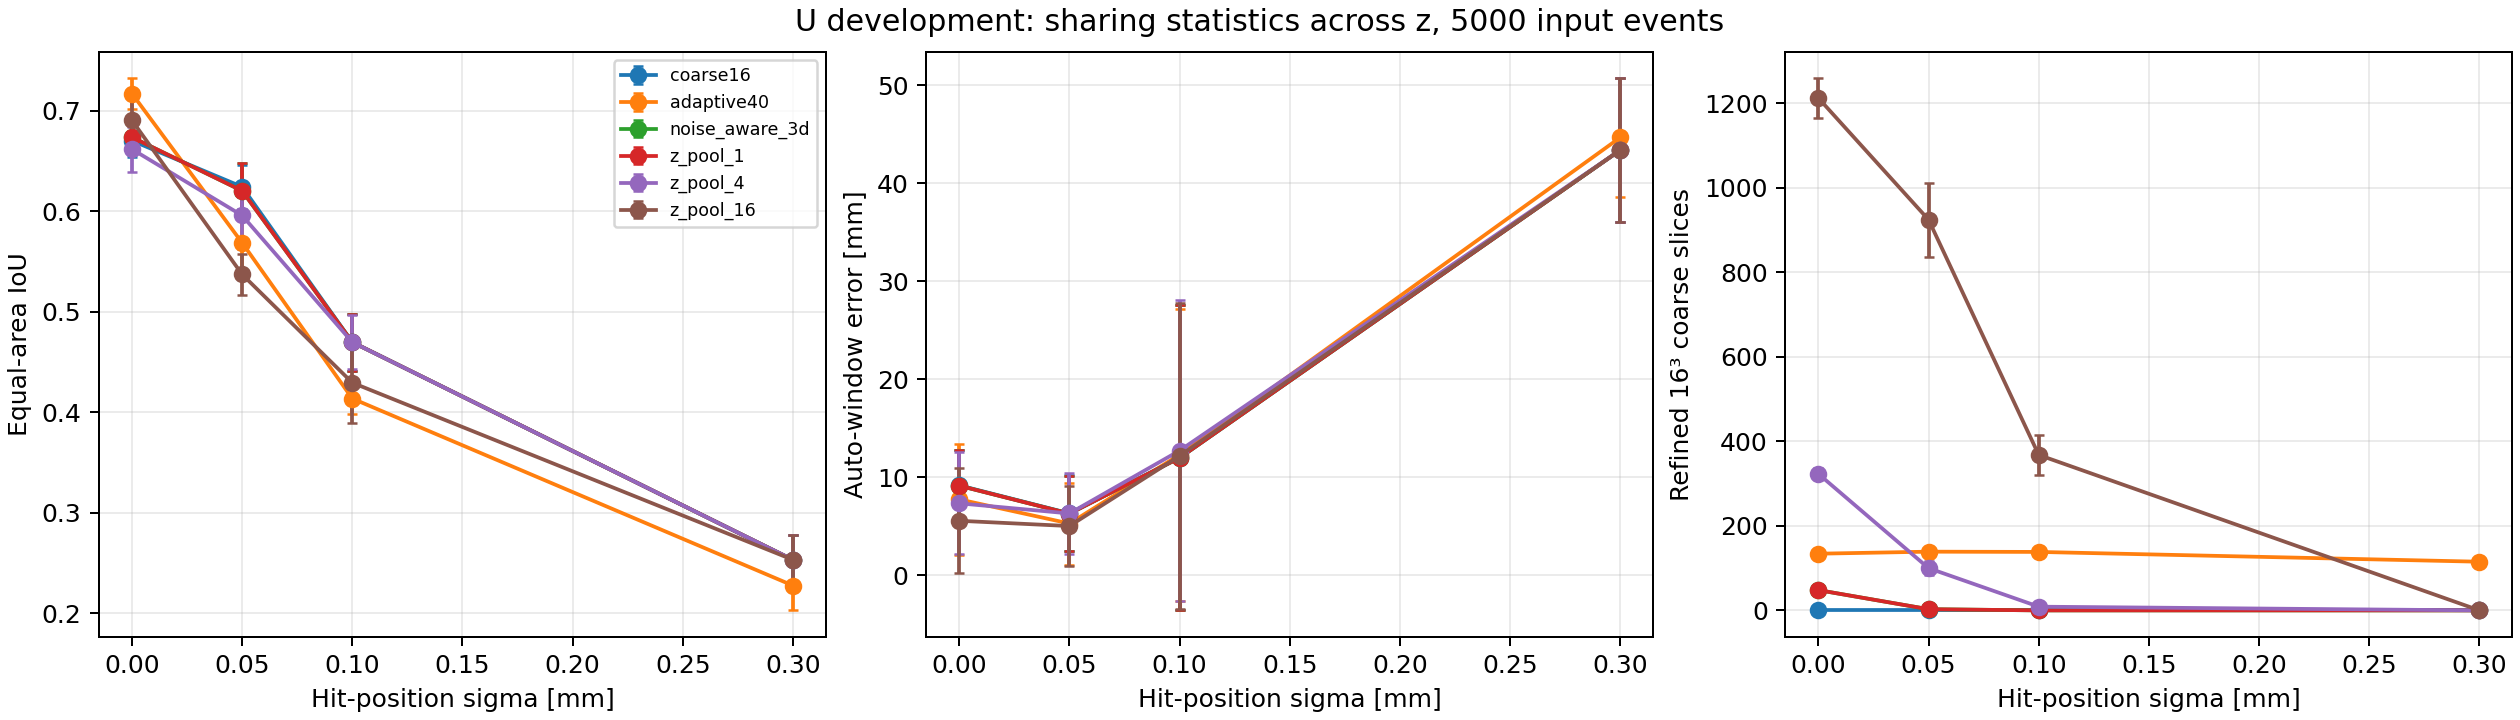

In [4]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

z_pool_dir = Path('z_pooled_refinement_results')  # Notebook 工作目录为 muon_analysis
z_pool_summary = pd.read_csv(z_pool_dir / 'summary.csv')
z_pool_pairs = pd.read_csv(z_pool_dir / 'paired_noisy_summary.csv')
display(z_pool_summary.loc[z_pool_summary.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_mean', 'auto_error_mm_mean',
     'refined_coarse_slices_mean', 'max_effective_events_mean']])
display(z_pool_pairs)
display(Image(filename=str(z_pool_dir / 'comparison_5000.png')))


## 邻域辅助、本地支撑的细分实验

上一节的整组 z 细分会把缺少本地事件的切片也一起细化。本节用 3×3 XY 邻域提出候选区，但只有粗 z 切片自身至少有两条通过筛选的事件，才执行 XY 细分；另比较按本地有效事件数收缩细节幅度的版本。目标真值只用于评分，这仍是 U 型开发数据上的探索。

5000 条输入、σ=0.05 mm 时，收缩版 IoU 约 0.623，接近粗网格 0.624；自动窗口误差约 4.92 mm，粗网格约 6.30 mm。但其他事件数、误差档位并不持续改善，因此暂不能称为已经验证的新方法。更多解释、限制和下一步见 `local_support_refinement_results/research_note.md`。


,method,position_sigma_mm,iou_mean,auto_error_mm_mean,refined_coarse_slices_mean,empty_or_singleton_slices_blocked_mean
8,adaptive40,0.00,0.717120,7.728166,134.2,NaN
9,adaptive40,0.05,0.568655,5.263151,139.0,NaN
10,adaptive40,0.10,0.413754,12.289618,138.4,NaN
11,adaptive40,0.30,0.227676,44.676454,115.2,NaN
20,coarse16,0.00,0.670228,9.158089,0.0,NaN
21,coarse16,0.05,0.624300,6.296382,0.0,NaN
22,coarse16,0.10,0.469820,11.970971,0.0,NaN
23,coarse16,0.30,0.253292,43.384484,0.0,NaN
32,local_hard,0.00,0.667629,9.115213,58.4,1758.4
33,local_hard,0.05,0.611374,4.944256,32.2,1791.0


,method,paired_n,iou_gain_mean,iou_win_fraction,global_error_reduction_mm_mean,auto_error_reduction_mm_mean
0,coarse16,45,0.033136,0.800000,0.034254,-1.392823
1,local_hard,45,0.027783,0.822222,0.021107,-1.343096
2,local_shrink,45,0.032028,0.822222,0.028911,-1.342388
3,z_pool_4,45,0.029371,0.777778,0.031706,-1.436348


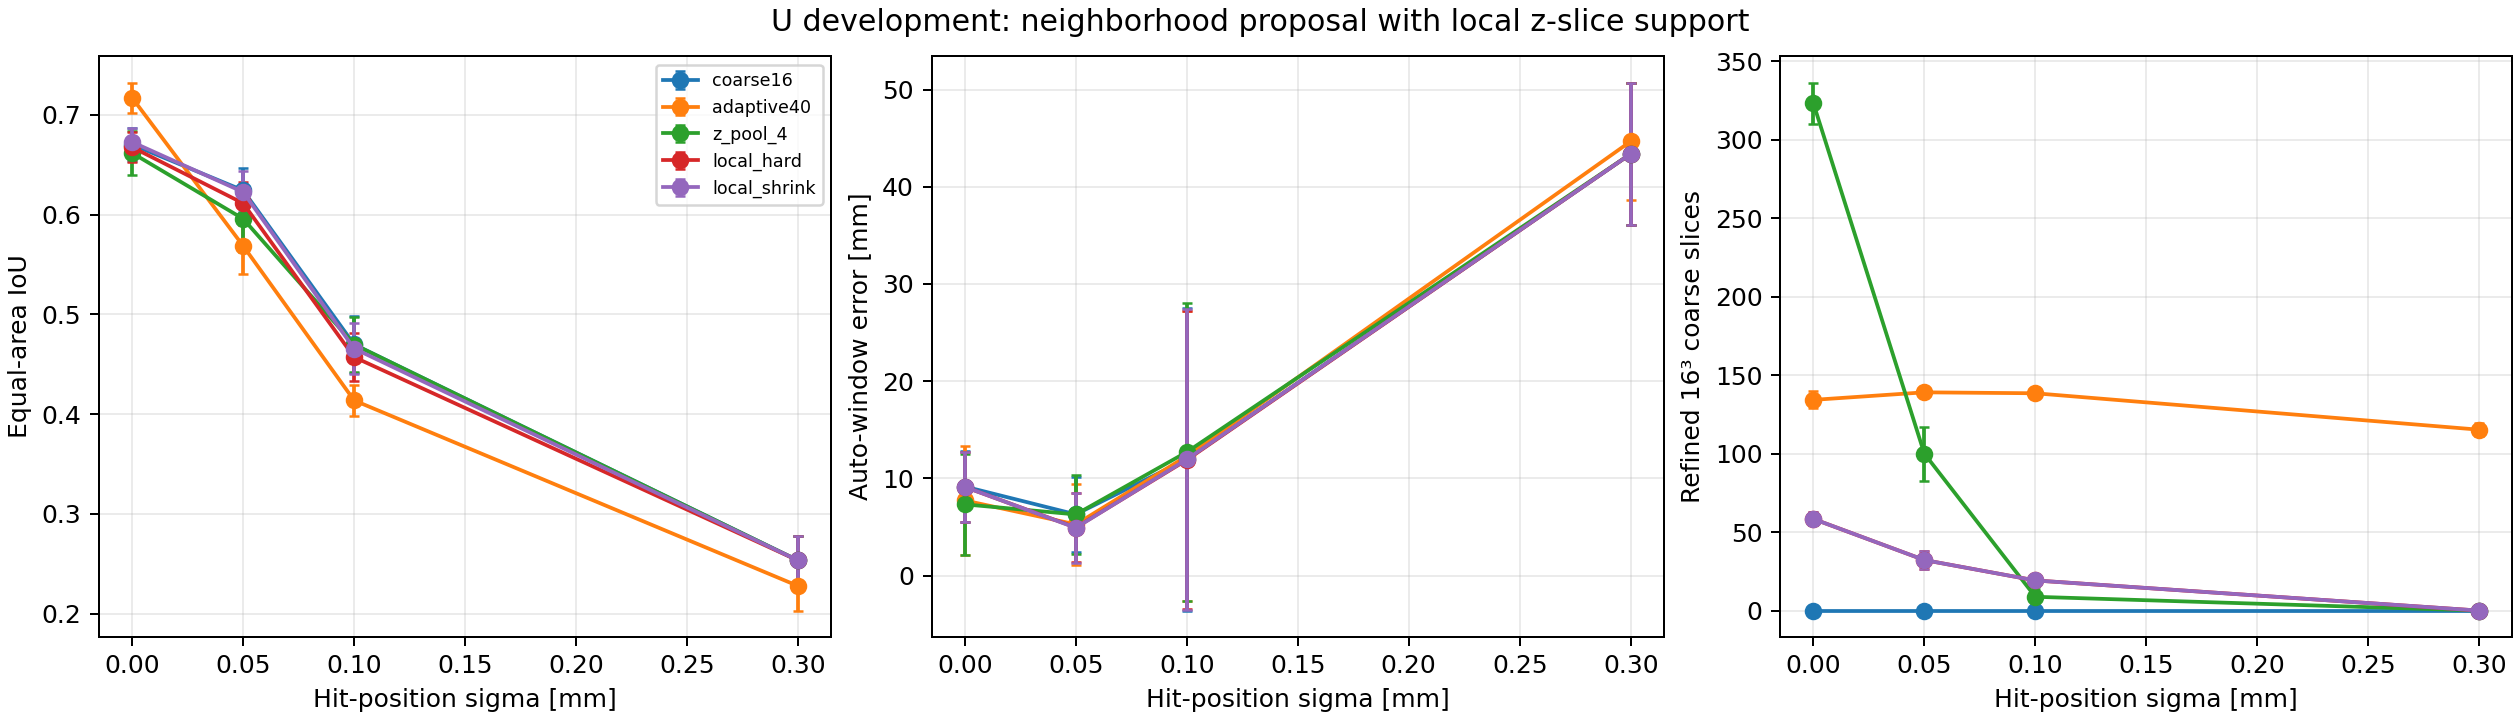

In [5]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

local_dir = Path('local_support_refinement_results')  # Notebook 工作目录为 muon_analysis
local_summary = pd.read_csv(local_dir / 'summary.csv')
local_pairs = pd.read_csv(local_dir / 'paired_noisy_summary.csv')
display(local_summary.loc[local_summary.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_mean', 'auto_error_mm_mean',
     'refined_coarse_slices_mean', 'empty_or_singleton_slices_blocked_mean']])
display(local_pairs)
display(Image(filename=str(local_dir / 'comparison_5000.png')))


## 局部细分归因与保守回退规则

本节只展示 U 型开发集的事后诊断。被细分切片位于目标几何包络外的比例随击中误差上升，但这不是单独的因果证据；σ=0.30 mm 没有细分切片，因此比例为空值而不是零。

保守规则只读取入选事件数、探测器层距和已知击中误差：入选 PoCA 数≥256 且角度噪声小于 3 mrad 上限的四分之一时用原 40% 细分，否则用粗网格。它仍在 U 型数据上形成，现阶段不是独立验证的创新方法。


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

fallback_dir = Path('refinement_fallback_results')  # Notebook 工作目录为 muon_analysis
display(pd.read_csv(fallback_dir / 'policy_summary.csv'))
display(pd.read_csv(fallback_dir / 'spatial_diagnostic_summary.csv'))
display(Image(filename=str(fallback_dir / 'diagnostic_5000.png')))


## 双分离铝块：冻结方法的独立形状验证

本轮只改变目标形状，不用新形状调任何阈值。双目标有 30 mm 空隙，因此除了 IoU，还要看左右目标的最低召回率与空隙伪影。单窗口定位误差假设一个连通目标，在这里不能作为主指标。

运行顺序：先用 `MUON_TARGET_SCENARIO=double_block` 和 `run_double_block_validation.mac` 生成单独 CSV，再运行 `run_double_block_validation.py`。下方只读取已经生成的结果。具体设置、负结果和局限见 `double_block_validation_results/research_note.md`。


,method,position_sigma_mm,iou_mean,iou_std,min_block_recall_mean,gap_false_positive_fraction_mean
8,adaptive40,0.00,0.651598,0.021374,0.751111,0.186667
9,adaptive40,0.05,0.527927,0.047801,0.637778,0.120000
10,adaptive40,0.10,0.314083,0.043182,0.431111,0.160000
11,adaptive40,0.30,0.129560,0.021241,0.168889,0.173333
20,coarse16,0.00,0.646866,0.006718,0.704444,0.186667
21,coarse16,0.05,0.563083,0.033369,0.637778,0.200000
22,coarse16,0.10,0.391524,0.028991,0.493333,0.200000
23,coarse16,0.30,0.169799,0.037570,0.240000,0.183333
32,fixed32,0.00,0.558756,0.024715,0.660000,0.156667
33,fixed32,0.05,0.449775,0.029967,0.580000,0.123333


,method,position_sigma_mm,iou_gain_mean,iou_win_fraction
8,adaptive40,0.00,0.004732,0.6
9,adaptive40,0.05,-0.035155,0.2
10,adaptive40,0.10,-0.077441,0.0
11,adaptive40,0.30,-0.040240,0.0
20,fixed32,0.00,-0.088110,0.0
21,fixed32,0.05,-0.113308,0.0
22,fixed32,0.10,-0.098067,0.0
23,fixed32,0.30,-0.014456,0.2
32,frozen_fallback,0.00,0.000124,0.4
33,frozen_fallback,0.05,0.000000,0.0


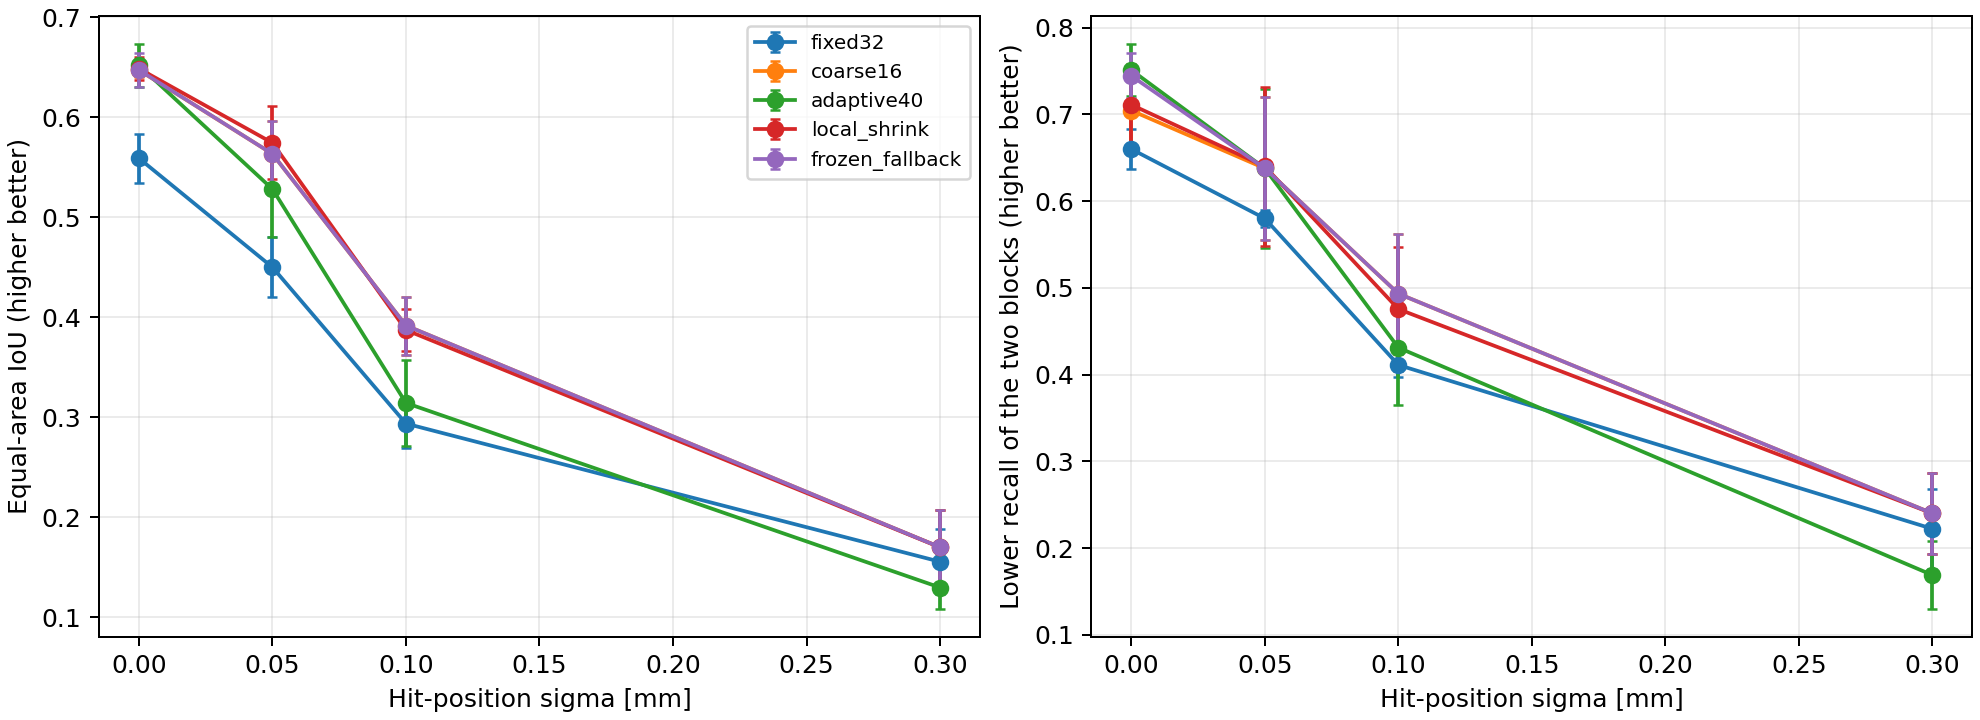

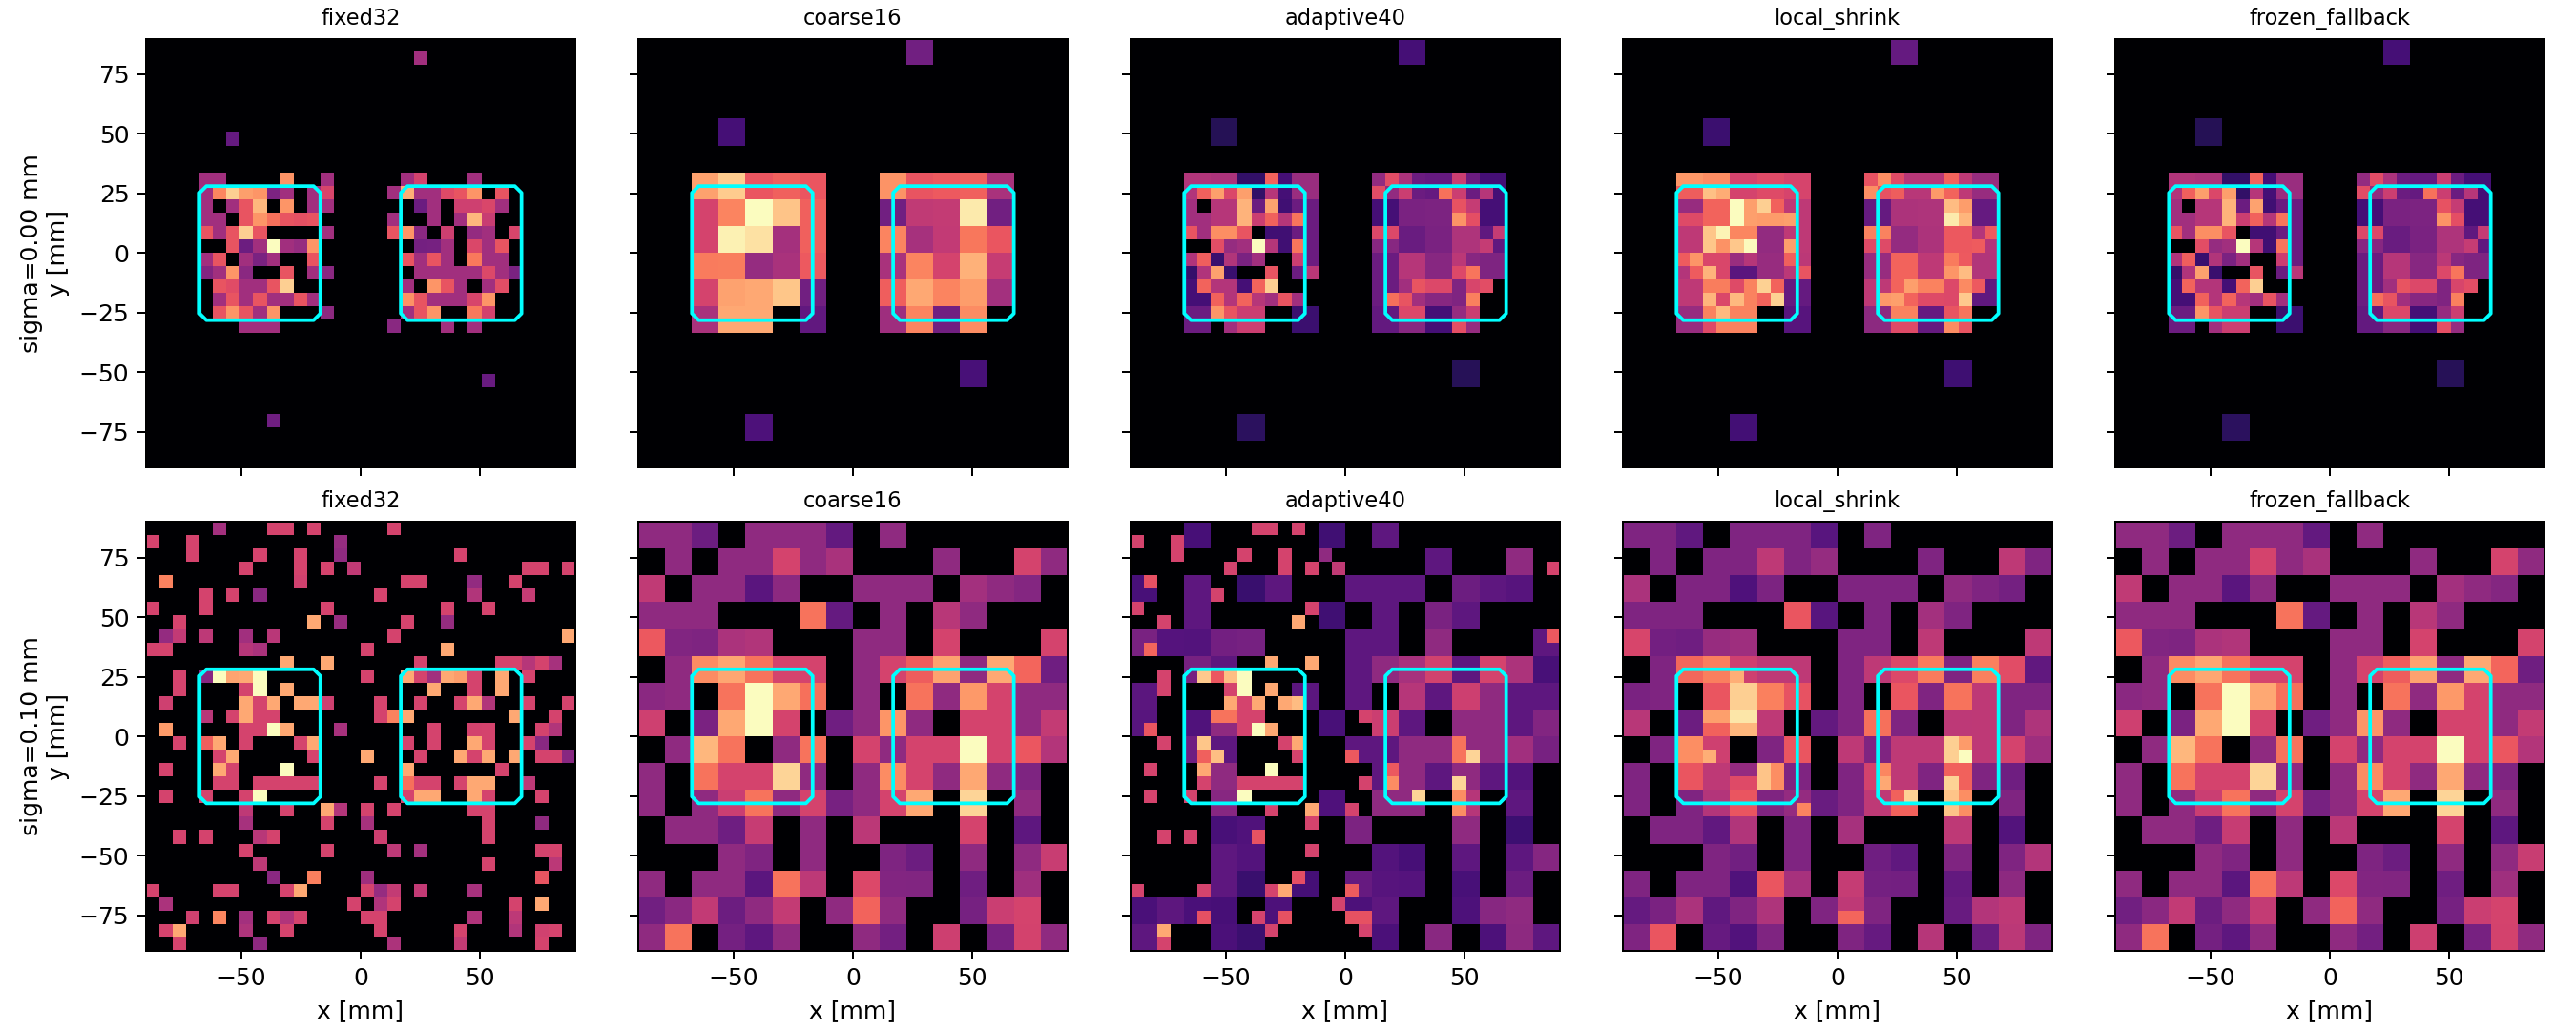

In [6]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

double_dir = Path('double_block_validation_results')  # Notebook 工作目录为 muon_analysis
double_summary = pd.read_csv(double_dir / 'summary.csv')
double_paired = pd.read_csv(double_dir / 'paired_summary.csv')
display(double_summary.loc[double_summary.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_mean', 'iou_std',
     'min_block_recall_mean', 'gap_false_positive_fraction_mean']])
display(double_paired.loc[double_paired.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_gain_mean', 'iou_win_fraction']])
display(Image(filename=str(double_dir / 'metrics_5000.png')))
display(Image(filename=str(double_dir / 'reconstruction_5000.png')))


## 下一轮方法：两半事件一致性控制的 2.5D 细化（尚无新场景结果）

思路：把同一粗 XY 单元的事件随机分成两半，检查四个子格的偏好能否重复出现；只把可重复的细节以部分权重写回，噪声越大则权重越小。这个一致性分数不是已校准的概率。公式、固定种子和未来 T 型场景的成功标准见 `CONFIDENCE_REFINEMENT_PROTOCOL.md`。

**注意：**下方只是合成事件的守恒测试，不是新场景成像效果；T 型数据尚未生成，不要把单元测试写成论文结果。


In [7]:
import numpy as np
import pandas as pd
from confidence_refinement import confidence_refined_volume

# 合成 24 条位于同一 XY 子格的事件，仅检查规则是否运行和权重是否守恒。
toy = pd.DataFrame({'poca_x_mm': np.ones(24),
                    'poca_y_mm': np.zeros(24),
                    'poca_z_mm': np.r_[np.full(12, -6.), np.full(12, 6.)],
                    'capped_weight': np.ones(24)})
toy_volume, toy_diagnostics = confidence_refined_volume(toy, sigma_mm=0.0, spacing_mm=100.0)
print('输入权重:', toy.capped_weight.sum(), '输出权重:', toy_volume.sum())
print('诊断量（不是成像性能）:', toy_diagnostics)


输入权重: 24.0 输出权重: 24.0
诊断量（不是成像性能）: {'supported_xy_cells': 1, 'mean_consistency_supported': 1.0, 'mean_alpha_nonzero': 0.8571428571428571, 'active_refined_xy_cells': 1, 'theta_noise_mrad': 0.0}


## T 型新场景：预注册两半一致性细化的独立验证

已按 `CONFIDENCE_REFINEMENT_PROTOCOL.md` 冻结的规则运行完整矩阵。预注册判定**未通过**：新规则在所有 N×σ 条件下的等面积 IoU 与粗16相同，并没有达到要求的 +0.02 增益。它偶尔给少数粗 XY 单元非零细节权重，因此 IoU 相同不代表原始图像每个数值都相同。请同时查看 `t_shape_independent_results/research_note.md` 中的失败解释和独立性边界；不要在本 T 型结果上改阈值后仍称它为未见测试。


预注册判定: {'criterion_met': False, 'eligible_gain_sigmas_mm': [], 'qualifying_sigmas_mm': [], 'required_gain': 0.02, 'required_paired_wins_out_of_5': 4, 'max_mean_loss_at_other_sigmas': 0.02, 'interpretation': 'descriptive practical criterion, not independent-simulation significance'}


,method,position_sigma_mm,iou_mean,iou_std,global_error_mm_mean,active_refined_xy_cells_mean
8,adaptive40,0.00,0.669749,0.015888,3.853381,NaN
9,adaptive40,0.05,0.506047,0.039385,4.931370,NaN
10,adaptive40,0.10,0.322249,0.016642,9.295220,NaN
11,adaptive40,0.30,0.141916,0.025303,13.948324,NaN
20,coarse16,0.00,0.676056,0.031671,3.851675,NaN
21,coarse16,0.05,0.616865,0.026907,4.872359,NaN
22,coarse16,0.10,0.381496,0.016555,9.211723,NaN
23,coarse16,0.30,0.150025,0.016076,13.842214,NaN
32,fixed32,0.00,0.598929,0.023929,3.884580,NaN
33,fixed32,0.05,0.443261,0.028026,4.975041,NaN


,position_sigma_mm,iou_gain_mean,iou_win_count
56,0.00,0.0,0
57,0.05,0.0,0
58,0.10,0.0,0
59,0.30,0.0,0


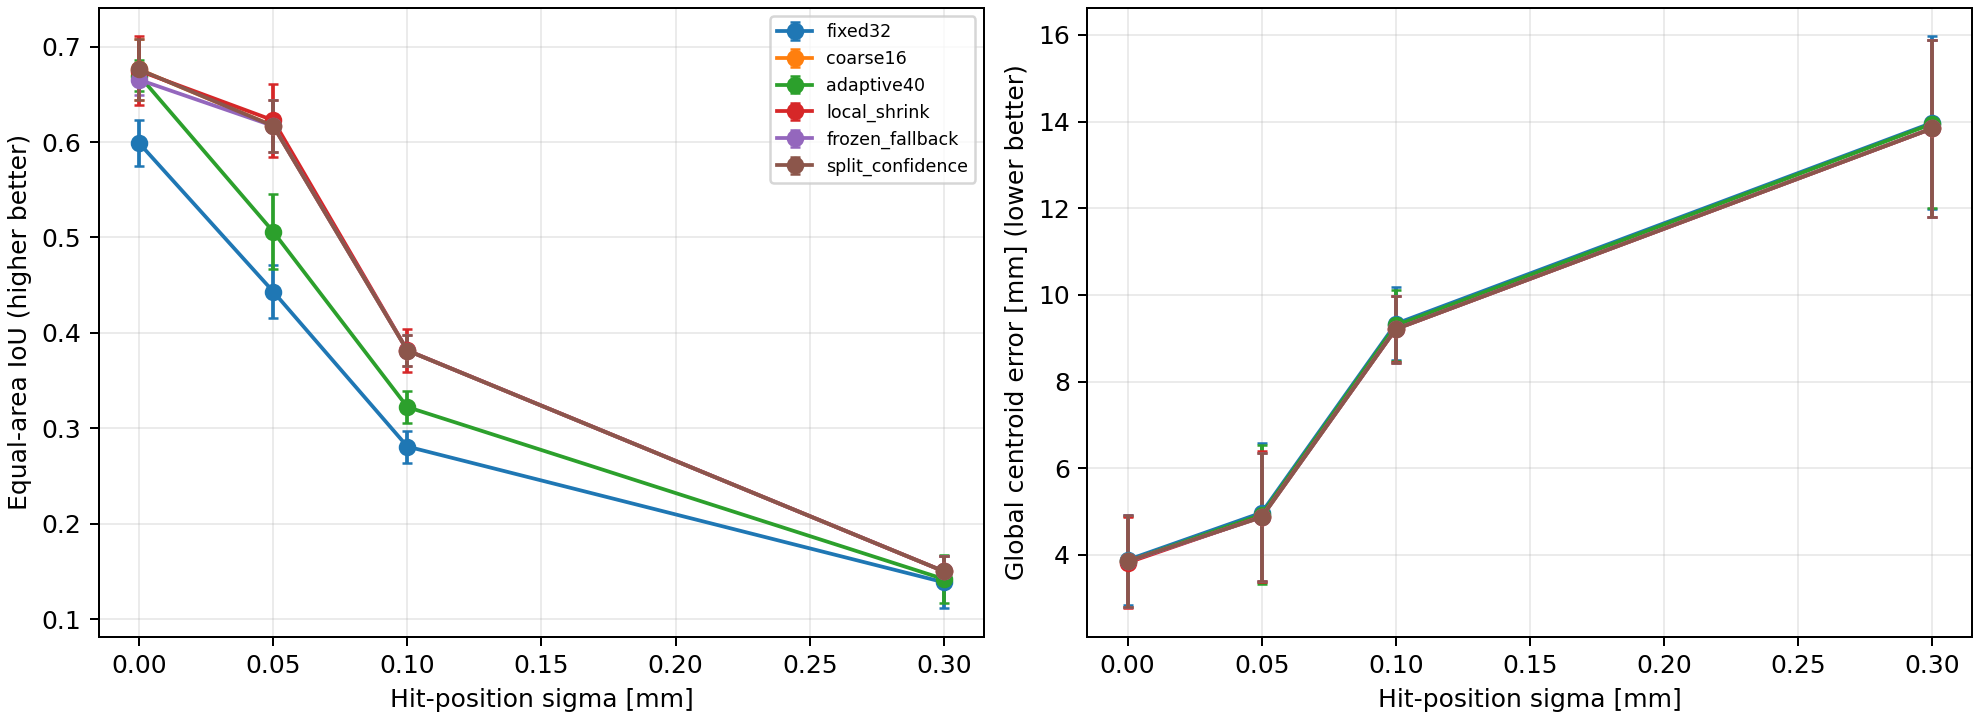

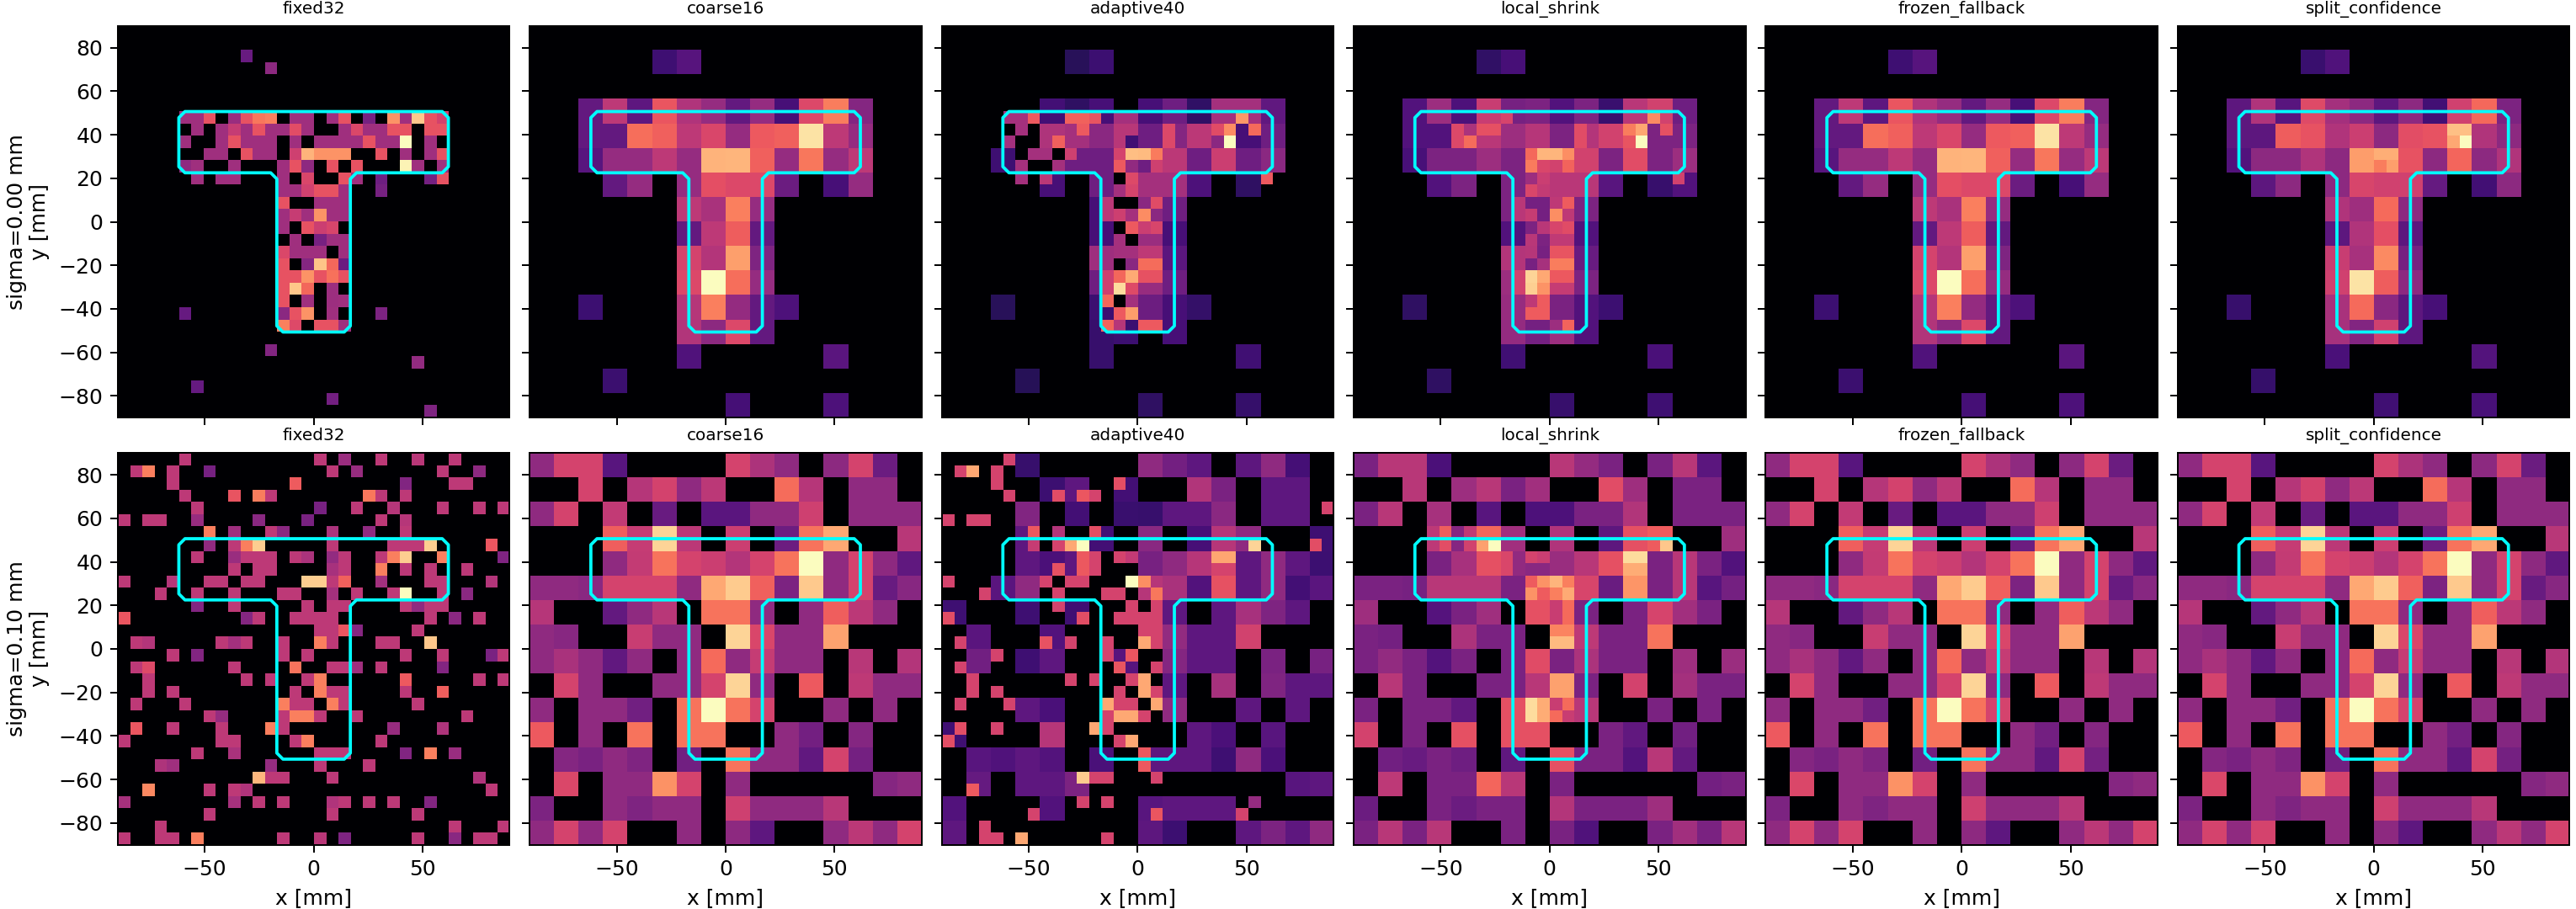

In [8]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

t_dir = Path('t_shape_independent_results')  # Notebook 工作目录为 muon_analysis
t_summary = pd.read_csv(t_dir / 'summary.csv')
t_pairs = pd.read_csv(t_dir / 'paired_summary.csv')
print('预注册判定:', json.loads((t_dir / 'verdict.json').read_text()))
display(t_summary.loc[t_summary.event_count == 5000,
    ['method', 'position_sigma_mm', 'iou_mean', 'iou_std',
     'global_error_mm_mean', 'active_refined_xy_cells_mean']])
display(t_pairs.loc[(t_pairs.event_count == 5000) &
    (t_pairs.method == 'split_confidence'),
    ['position_sigma_mm', 'iou_gain_mean', 'iou_win_count']])
display(Image(filename=str(t_dir / 'metrics_5000.png')))
display(Image(filename=str(t_dir / 'reconstruction_5000.png')))


## 为什么两半一致性细化没有改善轮廓：仅开发集诊断

这里只读 U、L、双铝块开发数据，不重新使用 T 型数据调参。筛选后的事件分散在大量粗 XY 单元，两半各≥4个有效事件的门槛几乎无法满足；少数非零细节系数也很小，三类开发场景的 Top-k 掩膜均未改变。该结论不等于证明某一个门槛是唯一原因，具体分解见 `split_confidence_diagnosis_results/research_note.md`。


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

gate_dir = Path('split_confidence_diagnosis_results')  # 工作目录为 muon_analysis
gate_summary = pd.read_csv(gate_dir / 'summary.csv')
display(gate_summary.loc[gate_summary.event_count == 5000,
    ['scenario', 'position_sigma_mm', 'selected_events_mean',
     'occupied_xy_cells_mean', 'split_supported_xy_cells_mean',
     'positive_consistency_xy_cells_mean', 'relative_image_l1_mean',
     'topk_changed_pixels_mean', 'iou_gain_vs_coarse_mean']])
display(Image(filename=str(gate_dir / 'gate_diagnosis_5000.png')))
